# 5. Evaluation

$$\text{Business Understanding} \longrightarrow \text{Data Understanding} \longrightarrow \text{Data Preparation} \longrightarrow \text{Modeling} \longrightarrow \boxed{\textbf{\textit{Evaluation}}} \longrightarrow \text{Deployment}$$

**Câu hỏi của Evaluation:** kết quả DM1/DM2 có đáp ứng BO1/BO2 không, và nếu tài xế / nền tảng làm theo thì **ai được, ai mất, bao nhiêu**?

## Executive Summary

| # | Insight | Bằng chứng (số liệu trong notebook) | Ai chịu tác động | Hành động |
|---|---|---|---|---|
| 1 | **Làm theo DM1, tài xế kiếm ít tiền hơn** | Top 20% ô theo điểm DM1: **−2.66 USD/giờ có khách** (≈ **−12.79 USD/ca**), tip **−0.48 USD/chuyến** so với hiện trạng; điểm DM1 tương quan **âm** với tip USD (ρ = **−0.41**) – 5.2.1 | Tài xế | **Không** dùng DM1 để gợi ý khu vực cho tài xế |
| 2 | **Năng lực của DM1 phần lớn là lỗi dữ liệu** | 140,071 chuyến thẻ RatecodeID = 99 có tip = 0 ở 100% chuyến; loại ra: AUC **0.7164 → 0.6226**, giá trị DM1 **2.93 → −0.05 USD/ca** – 5.1.4, 5.1.6 | Nền tảng | Sửa Data Preparation, lặp lại DM1 |
| 3 | **Lỗi dữ liệu dẫn tới né khu dân cư** | Điểm DM1 gốc khiến tài xế né **2,785 chuyến/ngày**, **73%** ngoài Manhattan (Central Harlem North, Crown Heights North, East New York) – 5.2.2 | Khách khu dân cư | Không xếp hạng khu vực bằng `high_tip` khi chưa loại artifact |
| 4 | **Nhãn `high_tip` phạt sai sân bay và chuyến dài** | Điểm DM1 sạch né **17,923 chuyến/ngày**, gồm JFK (**4,533**/ngày, tip TB **12.88 USD**, cao nhất) – 5.2.2; tip USD tăng 1.86 → 18.25 USD theo cước – 5.1.5 | Tài xế, khách sân bay | KPI tài xế = **thu nhập/giờ + tip USD** |
| 5 | **Tip do nút gợi ý quyết định** | **56.4%** chuyến tip đúng **20%** tổng trước tip; "tip thấp" tập trung ở khu ăn chơi đêm cuối tuần (không tip **9–12%**) và cước cố định (JFK flat 0.764 vs 0.836) – 5.4 | Khách, nền tảng | Thiết kế/minh bạch nút gợi ý tip |
| 6 | **Thống kê lịch sử đơn giản thắng model** | Top 20% ô theo thu nhập/giờ lịch sử: **+24.60 USD/giờ có khách** (51% chuyến chạm sân bay, chưa trừ thời gian xếp hàng), chỉ chứa **8.7%** chuyến – 5.2.1 | Tài xế | Dùng bảng KPI lịch sử theo ô, có A/B test |
| 7 | **"Tip cao – ít xe" nội đô: lợi ích nhỏ, phụ thuộc giả định** | +9.49 USD/giờ (giả định chờ 10′); bỏ giả định chờ: **+0.01 USD/giờ**; toàn hệ thống ≤ **1.47%** doanh thu tháng – 5.5 | Tài xế, nền tảng | Thí điểm thưởng ở Midtown đêm ngày thường, UES/UWS sáng cuối tuần |
| 8 | **DM2 dùng được cho điều phối** | Cụm sân bay (k=6): **8.5%** chuyến – **23.9%** doanh thu, xe bận **55.5 phút**/chuyến, **74.06** vs 78.91 USD/giờ có khách – 5.2.3 | Nền tảng | Triển khai thí điểm DM2 (k=6) cho lịch điều phối |

**Quyết định Evaluation:** DM2 → Deployment thí điểm · bản đồ KPI zone × khung giờ → thí điểm có A/B test · DM1 → **lặp lại vòng CRISP-DM** (5.7.4).

**Quy ước nhãn:** **[BẰNG CHỨNG TỪ DỮ LIỆU]** = số tính ở cell ngay trên · **[GIẢ THUYẾT/SUY LUẬN]** = giải thích dữ liệu không chứng minh trực tiếp · **[GIẢ ĐỊNH KỊCH BẢN]** = tham số do nhóm đặt.

**KPI:** tài xế → **thu nhập/giờ có khách** (fare + tip thẻ) và **tip USD/chuyến**; `high_tip` (tip/fare ≥ 15%) chỉ dùng để chấm DM1.

**Giới hạn nền tảng:** (1) tip tiền mặt không được ghi nhận → chỉ số tip chỉ đại diện khách trả thẻ; (2) không có ID xe/tài xế → "cung" chỉ là proxy từ dòng chảy chuyến đi.

| Phần | Nội dung |
|---|---|
| 5.0 | Tái tạo dữ liệu & model (kiểm tra trùng khớp) |
| 5.1 | Đánh giá DM1/DM2 theo mục tiêu business |
| 5.2 | **Tác động business của model** lên tài xế, khách hàng, điều phối |
| 5.3 | Khu vực × khung giờ, ma trận 2×2 |
| 5.4 | Kịch bản "tip thấp" – góc nhìn khách hàng |
| 5.5 | Kịch bản "tip cao nhưng ít xe" – góc nhìn tài xế |
| 5.6 | Đề xuất hành động & Deployment |
| 5.7 | Review quy trình & quyết định |

## 5.0. Thiết lập & tái tạo dữ liệu

Modeling không lưu model, file processed thiếu zone/tip/thời điểm → chạy lại đúng pipeline Data Preparation, **kiểm tra trùng khớp từng giá trị** với 2 file processed, rồi train lại model với cùng split/siêu tham số.

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import spearmanr

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.cluster import MiniBatchKMeans
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
                             recall_score, f1_score, confusion_matrix, silhouette_score)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_style("whitegrid")
plt.rcParams.update({"axes.titleweight": "bold", "axes.titlesize": 11, "axes.labelsize": 10})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

RANDOM_STATE = 42
RAW_PATH = "data/raw/yellow_tripdata_2026-05.parquet"
ZONE_PATH = "data/raw/taxi_zone_lookup.csv"
DM1_PATH = "data/processed/classification_data.parquet"
DM2_PATH = "data/processed/clustering_data.parquet"

# Fixed categorical colour order (validated reference palette) - never cycled
C_BLUE, C_ORANGE, C_AQUA, C_YELLOW, C_MAGENTA, C_GREEN, C_VIOLET, C_RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
CAT_COLORS = [C_BLUE, C_ORANGE, C_AQUA, C_YELLOW, C_MAGENTA, C_GREEN, C_VIOLET, C_RED]
C_GREY = "#898781"
DIV_CMAP = LinearSegmentedColormap.from_list("orange_grey_blue", [C_ORANGE, "#f0efec", C_BLUE])

TOD_ORDER = ["early_morning", "midday", "peak_hour", "late_night"]
SLOT_ORDER = [f"{d}|{t}" for d in ["weekday", "weekend"] for t in TOD_ORDER]
AIRPORT_ZONE_IDS = [1, 132, 138]   # Newark Airport, JFK Airport, LaGuardia Airport
UNKNOWN_ZONE_IDS = [264, 265]      # placeholder zones in the TLC lookup

In [2]:
def time_of_day(hour: pd.Series) -> np.ndarray:
    """Same 4 buckets as Data_Preparation 3.3."""
    return np.select(
        [(hour >= 6) & (hour < 10), (hour >= 10) & (hour < 16), (hour >= 16) & (hour < 20)],
        ["early_morning", "midday", "peak_hour"], default="late_night")


def slot_label(ts: pd.Series) -> pd.Series:
    """Day type x time_of_day, e.g. 'weekday|peak_hour' (8 slots in total)."""
    day_type = pd.Series(np.where(ts.dt.dayofweek >= 5, "weekend", "weekday"), index=ts.index)
    return day_type + "|" + pd.Series(time_of_day(ts.dt.hour), index=ts.index)


def build_clean_trips(raw_path: str, zone_path: str) -> pd.DataFrame:
    """Replicate the Data_Preparation cleaning pipeline while keeping the columns
    (zones, tip, total, timestamps) that the processed parquet files dropped."""
    df = pd.read_parquet(raw_path)
    df["ratecode_was_null"] = df["RatecodeID"].isna()

    # Null handling - identical to Data_Preparation 3.2a
    df[["congestion_surcharge", "Airport_fee"]] = df[["congestion_surcharge", "Airport_fee"]].fillna(0)
    df["passenger_count"] = df["passenger_count"].fillna(df["passenger_count"].mode().iloc[0])
    df["store_and_fwd_flag"] = df["store_and_fwd_flag"].fillna(df["store_and_fwd_flag"].mode().iloc[0])
    df["RatecodeID"] = df["RatecodeID"].fillna(99)

    # Business thresholds - Data_Preparation 3.2c (it found 0 duplicates, so no dedup step needed)
    df = df[(df["fare_amount"] > 0) & (df["fare_amount"] < 500)
            & (df["trip_distance"] > 0) & (df["trip_distance"] < 100)
            & (df["passenger_count"] >= 1) & (df["passenger_count"] <= 6)
            & (df["tpep_dropoff_datetime"] > df["tpep_pickup_datetime"])
            & (df["VendorID"].isin([1, 2, 6, 7]))].copy()
    df["trip_duration_min"] = ((df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"])
                               .dt.total_seconds() / 60.0).round(1)
    df = df[(df["trip_duration_min"] >= 1) & (df["trip_duration_min"] <= 180)]
    df = df[df["trip_distance"] / df["trip_duration_min"] * 60 <= 65].copy()

    # Constructed features - Data_Preparation 3.3
    ts = df["tpep_pickup_datetime"]
    df["pickup_hour"] = ts.dt.hour
    df["pickup_dayofweek"] = ts.dt.dayofweek
    df["is_weekend"] = df["pickup_dayofweek"].isin([5, 6]).astype(int)
    df["time_of_day"] = time_of_day(df["pickup_hour"])
    df["tip_percentage"] = np.where(df["fare_amount"] > 0, df["tip_amount"] / df["fare_amount"], 0)
    df["high_tip"] = (df["tip_percentage"] >= 0.15).astype(int)

    # Zone integration - Data_Preparation 3.4
    zones = pd.read_csv(zone_path)
    for side, key in [("pickup", "PULocationID"), ("dropoff", "DOLocationID")]:
        lookup = zones.rename(columns={"LocationID": key, "Borough": f"{side}_borough", "Zone": f"{side}_zone"})
        df = df.merge(lookup[[key, f"{side}_borough", f"{side}_zone"]], on=key, how="left")
    return df.reset_index(drop=True)


t0 = time.time()
trips = build_clean_trips(RAW_PATH, ZONE_PATH)
print(f"Rebuilt clean trips: {len(trips):,} rows ({time.time() - t0:.0f}s)")

# Verify the rebuild matches the processed files value-by-value
dm1_processed = pd.read_parquet(DM1_PATH)
dm2_processed = pd.read_parquet(DM2_PATH)
pd.testing.assert_frame_equal(
    trips.loc[trips["payment_type"] == 1, dm1_processed.columns].reset_index(drop=True),
    dm1_processed.reset_index(drop=True), check_dtype=False)
pd.testing.assert_frame_equal(
    trips[dm2_processed.columns].reset_index(drop=True),
    dm2_processed.reset_index(drop=True), check_dtype=False)
print(f"OK - identical to classification_data.parquet ({len(dm1_processed):,} rows) "
      f"and clustering_data.parquet ({len(dm2_processed):,} rows)")

Rebuilt clean trips: 3,886,428 rows (22s)


OK - identical to classification_data.parquet (2,643,757 rows) and clustering_data.parquet (3,886,428 rows)


In [3]:
for c in ["pickup_borough", "dropoff_borough"]:
    trips[c] = trips[c].fillna("Outside_NYC")          # same convention as Data_Modeling

trips["slot"] = slot_label(trips["tpep_pickup_datetime"])
trips["dropoff_slot"] = slot_label(trips["tpep_dropoff_datetime"])
trips["is_card"] = trips["payment_type"] == 1
trips["is_cash"] = trips["payment_type"] == 2
# RatecodeID == 99 as *recorded* by the meter (not a null that Data_Preparation filled with 99)
trips["is_r99"] = (trips["RatecodeID"] == 99) & ~trips["ratecode_was_null"]
trips["card_ok"] = trips["is_card"] & ~trips["is_r99"]          # analysis set for tip behaviour
trips["zero_tip"] = trips["tip_amount"] == 0
trips["revenue"] = trips["fare_amount"] + trips["tip_amount"]    # driver income proxy (card tips only)
trips["speed_mph"] = trips["trip_distance"] / trips["trip_duration_min"] * 60
trips["is_airport"] = (trips["PULocationID"].isin(AIRPORT_ZONE_IDS)
                       | trips["DOLocationID"].isin(AIRPORT_ZONE_IDS))
trips["has_airport_fee"] = trips["Airport_fee"] > 0      # charged only on LGA/JFK pickups
trips["pu_in_month"] = (trips["tpep_pickup_datetime"].dt.year.eq(2026)
                        & trips["tpep_pickup_datetime"].dt.month.eq(5))
trips["do_in_month"] = (trips["tpep_dropoff_datetime"].dt.year.eq(2026)
                        & trips["tpep_dropoff_datetime"].dt.month.eq(5))

overview = pd.Series({
    "all clean trips": len(trips),
    "card trips (= DM1)": int(trips["is_card"].sum()),
    "  of which recorded RatecodeID=99": int((trips["is_card"] & trips["is_r99"]).sum()),
    "card_ok (card, excl. RatecodeID=99)": int(trips["card_ok"].sum()),
    "cash trips": int(trips["is_cash"].sum()),
    "payment_type=0 (not reported)": int((trips["payment_type"] == 0).sum()),
    "pickups outside May 2026": int((~trips["pu_in_month"]).sum()),
})
print(overview.to_string())

# Pickups inside May 2026 with a known zone - base for every zone-level analysis
zone_src = trips[trips["pu_in_month"] & ~trips["PULocationID"].isin(UNKNOWN_ZONE_IDS)]
N_DAYS = 31
print("\nTip recorded (>0) by payment type:")
print(trips.groupby("payment_type")["zero_tip"].apply(lambda s: 1 - s.mean()).rename("share_tip_gt_0").round(4).to_string())

all clean trips                        3886428
card trips (= DM1)                     2643757
  of which recorded RatecodeID=99       140071
card_ok (card, excl. RatecodeID=99)    2503686
cash trips                              348009
payment_type=0 (not reported)           877060
pickups outside May 2026                    12



Tip recorded (>0) by payment type:


payment_type
0   0.0942
1   0.9019
2   0.0001
3   0.0003
4   0.0002


**[BẰNG CHỨNG TỪ DỮ LIỆU]** 3,886,428 chuyến sạch, trùng khớp 100% với 2 file processed.
- DM1 = 2,643,757 chuyến thẻ, trong đó **140,071** chuyến `RatecodeID = 99` → `card_ok` = 2,503,686.
- Tip > 0: thẻ **90.19%** · tiền mặt **0.01%** · không báo thanh toán (877,060 chuyến) **9.42%** → chỉ phân tích tip trên khách trả thẻ.

## 5.1. Đánh giá model theo mục tiêu business

### 5.1.1. Nhắc lại mục tiêu

| Mã | Mục tiêu nghiệp vụ (Business Understanding 1.3) | Bài toán mining | Câu hỏi Evaluation phải trả lời |
|---|---|---|---|
| **BO1** | Giúp tài xế quyết định *hoạt động ở đâu, khi nào* dựa trên khả năng tip cao | **DM1**: phân loại `high_tip` (tip/fare ≥ 15%, chỉ chuyến thẻ) | Model có xếp hạng chuyến/khu vực tốt hơn cảm tính không? Sai thì tốn gì? Yếu tố nào thật sự thúc đẩy tip? |
| **BO2** | Giúp điều phối nhận diện mẫu hình nhu cầu theo khu vực - khung giờ | **DM2**: KMeans k=5 trên đặc trưng thời gian dạng chu kỳ + borough one-hot | Các cụm có khác nhau về *giá trị kinh tế* (doanh thu, tip, sân bay) để điều phối khác nhau không? |

### 5.1.2. Tái tạo model DM1 (cùng dữ liệu, cùng split, cùng siêu tham số)

In [4]:
def engineer_dm1(X: pd.DataFrame) -> pd.DataFrame:
    """Same feature engineering as Data_Modeling 4.2.5."""
    X = X.copy()
    X["speed_mph"] = (X["trip_distance"] / X["trip_duration_min"] * 60).clip(0, 80)
    X["fare_per_mile"] = (X["fare_amount"] / X["trip_distance"].replace(0, np.nan)).fillna(0).clip(0, 100)
    X["fare_per_min"] = (X["fare_amount"] / X["trip_duration_min"]).clip(0, 50)
    X["hour_sin"] = np.sin(2 * np.pi * X["pickup_hour"] / 24)
    X["hour_cos"] = np.cos(2 * np.pi * X["pickup_hour"] / 24)
    X["same_borough"] = (X["pickup_borough"] == X["dropoff_borough"]).astype(int)
    return X


BASE_COLS = list(dm1_processed.columns.drop("high_tip"))
NUM_COLS = ["trip_distance", "trip_duration_min", "passenger_count", "pickup_hour",
            "pickup_dayofweek", "is_weekend", "fare_amount",
            "speed_mph", "fare_per_mile", "fare_per_min", "hour_sin", "hour_cos", "same_borough"]
CAT_COLS = ["time_of_day", "pickup_borough", "dropoff_borough"]

dm1 = trips[trips["is_card"]].reset_index(drop=True)
y1 = dm1["high_tip"]
# Splitting row positions with the same y/stratify/seed reproduces Data_Modeling's split exactly
idx_train, idx_test = train_test_split(np.arange(len(dm1)), test_size=0.2, stratify=y1,
                                       random_state=RANDOM_STATE)
X1_train = engineer_dm1(dm1.loc[idx_train, BASE_COLS])
X1_test = engineer_dm1(dm1.loc[idx_test, BASE_COLS])
y1_train, y1_test = y1.loc[idx_train], y1.loc[idx_test]
test_meta = dm1.loc[idx_test].copy()          # zone / tip / slot / RatecodeID for business slicing

lr_pipe = Pipeline([
    ("pre", ColumnTransformer([("num", StandardScaler(), NUM_COLS),
                               ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS)])),
    ("clf", LogisticRegression(max_iter=500, random_state=RANDOM_STATE)),
])
t0 = time.time()
lr_pipe.fit(X1_train, y1_train)
p_lr = lr_pipe.predict_proba(X1_test)[:, 1]
print(f"Logistic Regression refit: {time.time() - t0:.0f}s")

ordenc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
X1_train_enc, X1_test_enc = X1_train.copy(), X1_test.copy()
X1_train_enc[CAT_COLS] = ordenc.fit_transform(X1_train[CAT_COLS])
X1_test_enc[CAT_COLS] = ordenc.transform(X1_test[CAT_COLS])
cat_idx = [X1_train_enc.columns.get_loc(c) for c in CAT_COLS]

hgb = HistGradientBoostingClassifier(categorical_features=cat_idx, learning_rate=0.05, max_iter=500,
                                     max_leaf_nodes=63, l2_regularization=0.1, random_state=RANDOM_STATE)
t0 = time.time()
hgb.fit(X1_train_enc, y1_train)
p_hgb = hgb.predict_proba(X1_test_enc)[:, 1]
print(f"HistGradientBoosting refit: {time.time() - t0:.0f}s")

test_meta["p_hgb"], test_meta["p_lr"] = p_hgb, p_lr

# Reference values printed in Data_Modeling 4.2.8
repro = pd.DataFrame({
    "model": ["Logistic Regression", "HistGradientBoosting"],
    "AUC (Modeling nb)": [0.6825, 0.7165],
    "AUC (re-run)": [roc_auc_score(y1_test, p_lr), roc_auc_score(y1_test, p_hgb)],
    "PR_AUC (Modeling nb)": [0.8649, 0.8872],
    "PR_AUC (re-run)": [average_precision_score(y1_test, p_lr), average_precision_score(y1_test, p_hgb)],
})
print(repro.to_string(index=False))

Logistic Regression refit: 36s


HistGradientBoosting refit: 193s


               model  AUC (Modeling nb)  AUC (re-run)  PR_AUC (Modeling nb)  PR_AUC (re-run)
 Logistic Regression             0.6825        0.6825                0.8649           0.8649
HistGradientBoosting             0.7165        0.7164                0.8872           0.8872


**[BẰNG CHỨNG TỪ DỮ LIỆU]** LogReg khớp tuyệt đối (AUC 0.6825); HGB AUC 0.7164 vs 0.7165 (lệch do tính toán song song) → đang đánh giá đúng model của Modeling.

### 5.1.3. DM1: precision/recall từng lớp, lift & gain theo decile

**Lift decile d** = tỷ lệ lớp mục tiêu trong decile ÷ tỷ lệ chung · **Cumulative gain** = % chuyến của lớp mục tiêu gom được trong top d decile.

In [5]:
THRESH = 0.5
pred_hgb = (p_hgb >= THRESH).astype(int)
base_rate = y1_test.mean()


def class_metrics(y, pred, label):
    return {"class": "high_tip (1)" if label == 1 else "low_tip (0)",
            "precision": precision_score(y, pred, pos_label=label),
            "recall": recall_score(y, pred, pos_label=label),
            "f1": f1_score(y, pred, pos_label=label),
            "support": int((y == label).sum())}


tn, fp, fn, tp = confusion_matrix(y1_test, pred_hgb).ravel()
print(f"Test set: {len(y1_test):,} card trips | base rate high_tip = {base_rate:.4f}")
print(pd.DataFrame([class_metrics(y1_test, pred_hgb, 1), class_metrics(y1_test, pred_hgb, 0)]).to_string(index=False))
print(f"\nConfusion counts @0.5: TP={tp:,}  FP (báo nhầm high)={fp:,}  FN (bỏ sót high)={fn:,}  TN={tn:,}")


def decile_table(y, score, extra=None):
    """Rank by score (highest first), cut into 10 equal deciles and summarise each one."""
    d = pd.DataFrame({"y": np.asarray(y), "score": np.asarray(score)})
    for name, values in (extra or {}).items():
        d[name] = np.asarray(values)
    d["decile"] = pd.qcut(d["score"].rank(method="first", ascending=False), 10, labels=range(1, 11)).astype(int)
    agg = {"n": ("y", "size"), "mean_score": ("score", "mean"), "positives": ("y", "sum")}
    agg.update({f"share_{name}": (name, "mean") for name in (extra or {})})
    t = d.groupby("decile").agg(**agg)
    t["rate"] = t["positives"] / t["n"]
    t["lift"] = t["rate"] / d["y"].mean()
    t["cum_gain"] = t["positives"].cumsum() / d["y"].sum()
    t["cum_lift"] = (t["positives"].cumsum() / t["n"].cumsum()) / d["y"].mean()
    return t


r99_flag = test_meta["is_r99"].values
dec_high_hgb = decile_table(y1_test, p_hgb)
dec_high_lr = decile_table(y1_test, p_lr)
dec_low_hgb = decile_table(1 - y1_test, 1 - p_hgb, extra={"r99": r99_flag})
dec_low_lr = decile_table(1 - y1_test, 1 - p_lr)

print("\n[HGB] Target = high_tip, decile 1 = highest P(high_tip)")
print(dec_high_hgb[["n", "mean_score", "rate", "lift", "cum_gain", "cum_lift"]].to_string())
print("\n[HGB] Target = low_tip, decile 1 = lowest P(high_tip)")
print(dec_low_hgb[["n", "rate", "lift", "cum_gain", "cum_lift", "share_r99"]].to_string())

Test set: 528,752 card trips | base rate high_tip = 0.7877


       class  precision  recall     f1  support
high_tip (1)     0.8310  0.9978 0.9068   416505
 low_tip (0)     0.9675  0.2471 0.3937   112247

Confusion counts @0.5: TP=415,573  FP (báo nhầm high)=84,506  FN (bỏ sót high)=932  TN=27,741



[HGB] Target = high_tip, decile 1 = highest P(high_tip)
            n  mean_score   rate   lift  cum_gain  cum_lift
decile                                                     
1       52876      0.9356 0.9341 1.1859    0.1186    1.1859
2       52875      0.8875 0.8873 1.1264    0.2312    1.1561
3       52875      0.8749 0.8743 1.1100    0.3422    1.1407
4       52875      0.8608 0.8604 1.0923    0.4514    1.1286
5       52875      0.8361 0.8406 1.0671    0.5582    1.1163
6       52875      0.8123 0.8147 1.0343    0.6616    1.1026
7       52875      0.7983 0.7966 1.0113    0.7627    1.0896
8       52875      0.7817 0.7828 0.9938    0.8621    1.0776
9       52875      0.7537 0.7534 0.9564    0.9577    1.0642
10      52876      0.3348 0.3329 0.4226    1.0000    1.0000

[HGB] Target = low_tip, decile 1 = lowest P(high_tip)
            n   rate   lift  cum_gain  cum_lift  share_r99
decile                                                    
1       52876 0.6671 3.1427    0.3143    3.1427   

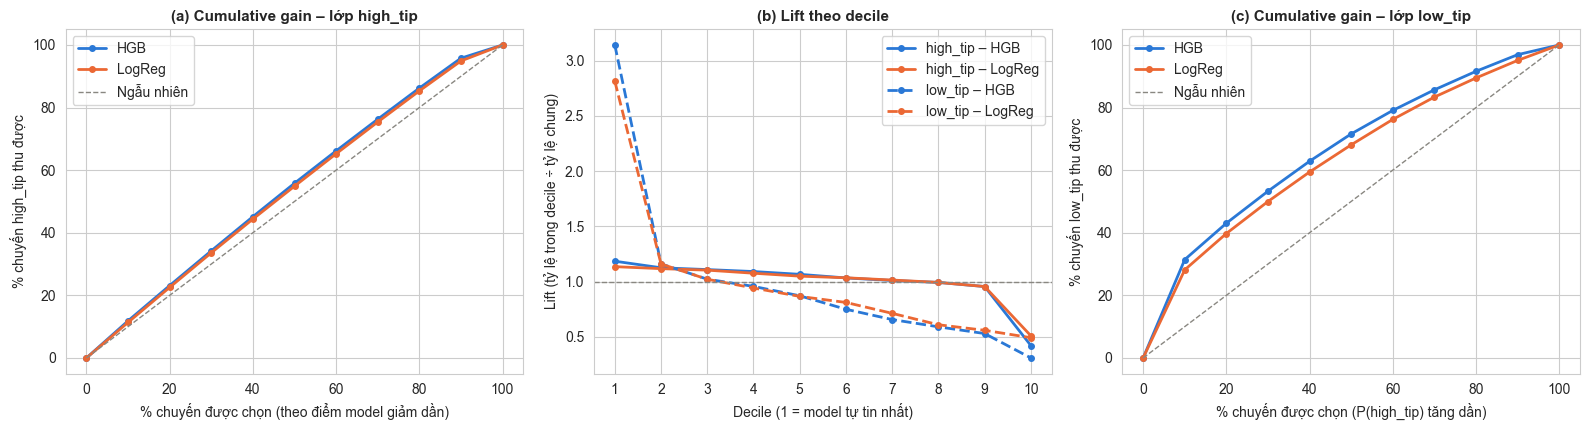

In [6]:
x_pct = np.arange(0, 101, 10)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

ax = axes[0]
for t, name, col in [(dec_high_hgb, "HGB", C_BLUE), (dec_high_lr, "LogReg", C_ORANGE)]:
    ax.plot(x_pct, np.r_[0, t["cum_gain"].values * 100], marker="o", ms=4, lw=2, color=col, label=name)
ax.plot([0, 100], [0, 100], ls="--", lw=1, color=C_GREY, label="Ngẫu nhiên")
ax.set_title("(a) Cumulative gain – lớp high_tip")
ax.set_xlabel("% chuyến được chọn (theo điểm model giảm dần)")
ax.set_ylabel("% chuyến high_tip thu được")
ax.legend()

ax = axes[1]
# colour = model (as in panels a/c), line style = target class
for t, name, col, ls in [(dec_high_hgb, "high_tip – HGB", C_BLUE, "-"), (dec_high_lr, "high_tip – LogReg", C_ORANGE, "-"),
                         (dec_low_hgb, "low_tip – HGB", C_BLUE, "--"), (dec_low_lr, "low_tip – LogReg", C_ORANGE, "--")]:
    ax.plot(t.index, t["lift"], marker="o", ms=4, lw=2, ls=ls, color=col, label=name)
ax.axhline(1, ls="--", lw=1, color=C_GREY)
ax.set_title("(b) Lift theo decile")
ax.set_xlabel("Decile (1 = model tự tin nhất)")
ax.set_ylabel("Lift (tỷ lệ trong decile ÷ tỷ lệ chung)")
ax.set_xticks(range(1, 11))
ax.legend()

ax = axes[2]
for t, name, col in [(dec_low_hgb, "HGB", C_BLUE), (dec_low_lr, "LogReg", C_ORANGE)]:
    ax.plot(x_pct, np.r_[0, t["cum_gain"].values * 100], marker="o", ms=4, lw=2, color=col, label=name)
ax.plot([0, 100], [0, 100], ls="--", lw=1, color=C_GREY, label="Ngẫu nhiên")
ax.set_title("(c) Cumulative gain – lớp low_tip")
ax.set_xlabel("% chuyến được chọn (P(high_tip) tăng dần)")
ax.set_ylabel("% chuyến low_tip thu được")
ax.legend()
plt.tight_layout()
plt.show()

**Insight:** DM1 gần như không giúp nhận diện chuyến tip cao; giá trị chỉ nằm ở 10% chuyến bị chấm thấp nhất.

**[BẰNG CHỨNG TỪ DỮ LIỆU]**
- Tỷ lệ nền high_tip **78.77%**; precision lớp high_tip **83.10%** → chỉ hơn đoán bừa 4.3 điểm %. Top 30% điểm cao gom **34.2%** chuyến high_tip (ngẫu nhiên: 30%).
- Lớp low_tip: decile thấp nhất có lift **3.14**, gom **31.4%** chuyến tip thấp — nhưng **52.5%** decile này là chuyến `RatecodeID = 99` (artifact, xem 5.1.6).
- Ngưỡng 0.5: recall low_tip **24.71%** → bỏ sót 3/4 chuyến tip thấp.

**Tác động:** tài xế không có lợi khi tin nhãn "tip cao" từng chuyến; nền tảng không nên dùng DM1 để cảnh báo từng chuyến.

### 5.1.4. Chi phí của việc đoán sai

| Lỗi | Tài xế | Nền tảng |
|---|---|---|
| **FN – bỏ sót tip cao** (thật high, model nói low) | Bỏ lỡ khu/khung giờ đáng chạy | Phân bổ xe kém tối ưu |
| **FP – báo nhầm** (thật low, model nói high) | Chạy tới nơi được "hứa" tip cao nhưng không được, mất niềm tin | Trả thưởng khu vực sai chỗ |

**[GIẢ ĐỊNH KỊCH BẢN]** mỗi lỗi = chênh lệch tip TB giữa chuyến high và low (đo trên test) × hệ số FN:FP ∈ {1:2, 1:1, 2:1}.

Mean tip (test): high_tip = $5.07 | low_tip = $1.27 | gap = $3.80/trip


   scenario  threshold  precision_high  recall_high  recall_low  cost_per_1000_trips  cost_at_0.5
FN:FP = 1:2     0.6500          0.8330       0.9915      0.2624             607.6502     610.6181
FN:FP = 1:1     0.5000          0.8310       0.9978      0.2471             613.9668     613.9668
FN:FP = 2:1     0.4000          0.8302       0.9988      0.2420             618.6377     620.6642


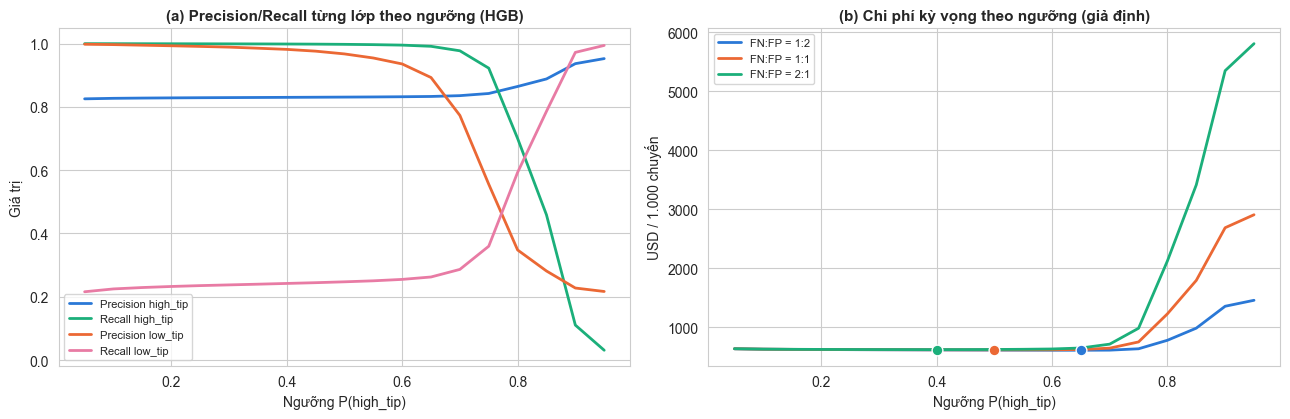

In [7]:
y_test_arr = y1_test.values
tip_high = test_meta.loc[y_test_arr == 1, "tip_amount"].mean()
tip_low = test_meta.loc[y_test_arr == 0, "tip_amount"].mean()
TIP_GAP = tip_high - tip_low
print(f"Mean tip (test): high_tip = ${tip_high:.2f} | low_tip = ${tip_low:.2f} | gap = ${TIP_GAP:.2f}/trip")

rows = []
for t in np.round(np.arange(0.05, 0.96, 0.05), 2):
    pred = (p_hgb >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y1_test, pred).ravel()
    rows.append({"threshold": t,
                 "precision_high": tp_ / (tp_ + fp_) if tp_ + fp_ else np.nan,
                 "recall_high": tp_ / (tp_ + fn_),
                 "precision_low": tn_ / (tn_ + fn_) if tn_ + fn_ else np.nan,
                 "recall_low": tn_ / (tn_ + fp_),
                 "FP": fp_, "FN": fn_})
sweep = pd.DataFrame(rows)

COST_RATIOS = {"FN:FP = 1:2": 0.5, "FN:FP = 1:1": 1.0, "FN:FP = 2:1": 2.0}   # cost_FN / cost_FP
for name, ratio in COST_RATIOS.items():
    # expected cost in USD per 1,000 test trips
    sweep[name] = (sweep["FP"] * TIP_GAP + sweep["FN"] * ratio * TIP_GAP) / len(y1_test) * 1000

best_thr = pd.DataFrame([
    {"scenario": name, **sweep.loc[sweep[name].idxmin(),
                                   ["threshold", "precision_high", "recall_high", "recall_low"]].to_dict(),
     "cost_per_1000_trips": sweep[name].min(),
     "cost_at_0.5": sweep.loc[np.isclose(sweep["threshold"], 0.5), name].iloc[0]}
    for name in COST_RATIOS])
print(best_thr.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
for col, name, c in [("precision_high", "Precision high_tip", C_BLUE), ("recall_high", "Recall high_tip", C_AQUA),
                     ("precision_low", "Precision low_tip", C_ORANGE), ("recall_low", "Recall low_tip", C_MAGENTA)]:
    ax.plot(sweep["threshold"], sweep[col], lw=2, color=c, label=name)
ax.set_title("(a) Precision/Recall từng lớp theo ngưỡng (HGB)")
ax.set_xlabel("Ngưỡng P(high_tip)")
ax.set_ylabel("Giá trị")
ax.legend(fontsize=8)

ax = axes[1]
for (name, _), c in zip(COST_RATIOS.items(), [C_BLUE, C_ORANGE, C_AQUA]):
    ax.plot(sweep["threshold"], sweep[name], lw=2, color=c, label=name)
    i = sweep[name].idxmin()
    ax.scatter(sweep.loc[i, "threshold"], sweep.loc[i, name], s=60, color=c, edgecolor="white", zorder=3)
ax.set_title("(b) Chi phí kỳ vọng theo ngưỡng (giả định)")
ax.set_xlabel("Ngưỡng P(high_tip)")
ax.set_ylabel("USD / 1.000 chuyến")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

[assumption] trips per 8h shift at 60% occupancy: 15.2
                 subset  cost_without_model  cost_with_DM1  saving_per_trip  saving_per_shift
           Toàn bộ test              0.8070         0.6140           0.1930            2.9300
Test loại RatecodeID=99              0.6390         0.6420          -0.0030           -0.0450


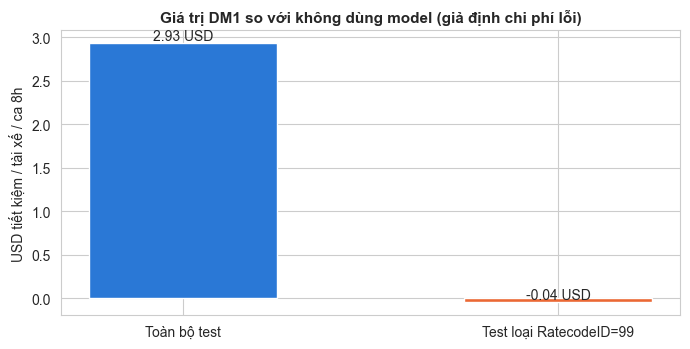

In [8]:
# Money value of DM1 vs. not using it (= always assume "high tip"), per driver shift
SHIFT_H, UTIL = 8, 0.6          # [assumption] 8-hour shift, 60% of the time with a passenger
trips_per_shift = SHIFT_H * 60 * UTIL / test_meta["trip_duration_min"].mean()


def error_cost_per_trip(y, pred):
    # FN:FP = 1:1, every error priced at TIP_GAP
    fp = ((pred == 1) & (y == 0)).sum()
    fn = ((pred == 0) & (y == 1)).sum()
    return (fp + fn) * TIP_GAP / len(y)


rows = []
for name, mask in [("Toàn bộ test", np.ones(len(y_test_arr), bool)), ("Test loại RatecodeID=99", ~r99_flag)]:
    y, pred = y_test_arr[mask], pred_hgb[mask]
    c_no_model, c_model = error_cost_per_trip(y, np.ones_like(y)), error_cost_per_trip(y, pred)
    rows.append({"subset": name, "cost_without_model": c_no_model, "cost_with_DM1": c_model,
                 "saving_per_trip": c_no_model - c_model,
                 "saving_per_shift": (c_no_model - c_model) * trips_per_shift})
value_tbl = pd.DataFrame(rows)
print(f"[assumption] trips per {SHIFT_H}h shift at {UTIL:.0%} occupancy: {trips_per_shift:.1f}")
print(value_tbl.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(value_tbl["subset"], value_tbl["saving_per_shift"], color=[C_BLUE, C_ORANGE], width=0.5)
for i, v in enumerate(value_tbl["saving_per_shift"]):
    ax.text(i, v, f"{v:.2f} USD", ha="center", va="bottom")
ax.set_title("Giá trị DM1 so với không dùng model (giả định chi phí lỗi)")
ax.set_ylabel(f"USD tiết kiệm / tài xế / ca {SHIFT_H}h")
plt.tight_layout()
plt.show()

**Insight:** ở cấp từng chuyến, chỉnh ngưỡng không tạo giá trị; phần tiết kiệm của DM1 gần như toàn bộ đến từ artifact.

**[BẰNG CHỨNG TỪ DỮ LIỆU + GIẢ ĐỊNH KỊCH BẢN]**
- Tip TB: high **5.07 USD**, low **1.27 USD** → mỗi lỗi định giá **3.80 USD**.
- Ngưỡng 0.5: **84,506 FP** vs **932 FN** → model gần như luôn nói "tip cao".
- Đổi tỷ lệ chi phí FN:FP (1:2 → 2:1): ngưỡng tối ưu 0.65 → 0.40, chi phí chỉ giảm **< 0.5%** (607.65–618.64 USD/1.000 chuyến).
- Quy ra tiền (**[GIẢ ĐỊNH]** ca 8h, 60% thời gian có khách → **15.2** chuyến/ca): DM1 tiết kiệm **2.93 USD/ca** so với không dùng model trên toàn test, nhưng **−0.05 USD/ca** khi loại RatecodeID = 99.

**Tác động:** tài xế — giá trị DM1 ở cấp chuyến ≈ 0 khi dữ liệu sạch; nền tảng — báo nhầm (FP) chiếm gần hết chi phí, gắn thưởng theo dự đoán từng chuyến sẽ trả sai chỗ.

### 5.1.5. Yếu tố nào thúc đẩy `high_tip`?

Permutation importance từng biến (như Modeling) và **theo nhóm yếu tố nghiệp vụ** (xáo đồng thời các biến cùng nhóm → không bị che bởi biến tương quan).

Single-feature permutation importance (AUC drop):
fare_amount         0.1541
fare_per_min        0.0285
fare_per_mile       0.0153
trip_duration_min   0.0151
trip_distance       0.0080
pickup_hour         0.0075
pickup_borough      0.0058
speed_mph           0.0057
dropoff_borough     0.0053
same_borough        0.0051
pickup_dayofweek    0.0027
hour_cos            0.0010
hour_sin            0.0007
passenger_count     0.0006
time_of_day         0.0001
is_weekend          0.0000

Grouped permutation importance (AUC drop):
                               group  auc_drop_mean  auc_drop_std
Giá cước (fare, fare/mile, fare/min)         0.2044        0.0025
            Quãng đường & thời lượng         0.0193        0.0012
     Thời gian (giờ, thứ, cuối tuần)         0.0156        0.0012
           Khu vực (borough đón/trả)         0.0144        0.0006
                       Số hành khách         0.0004        0.0002


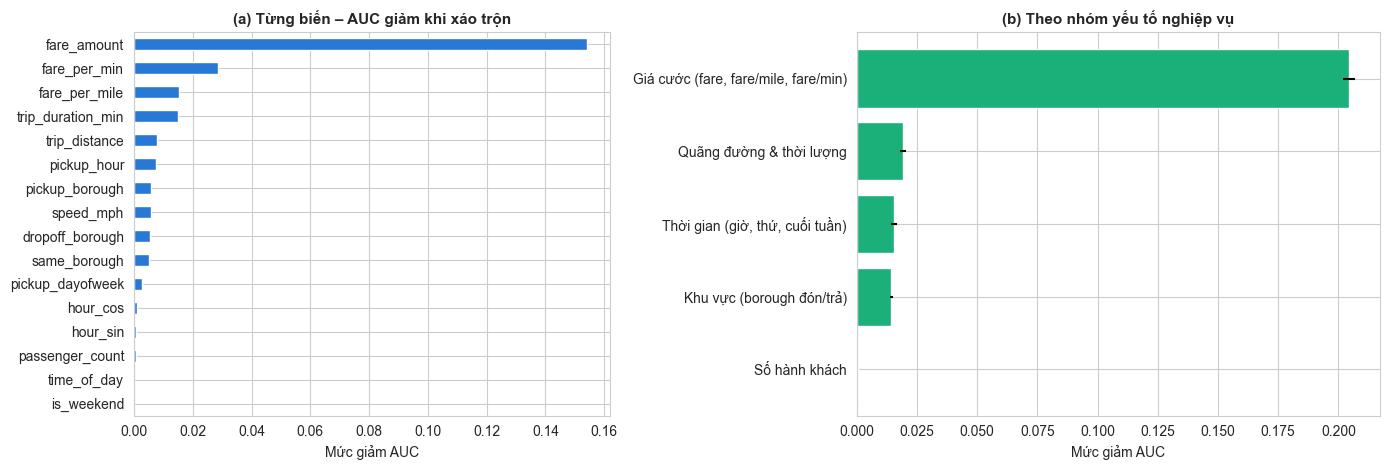

In [9]:
sample_idx = X1_test_enc.sample(60000, random_state=RANDOM_STATE).index
X_imp, y_imp = X1_test_enc.loc[sample_idx], y1_test.loc[sample_idx]

perm = permutation_importance(hgb, X_imp, y_imp, n_repeats=5, random_state=RANDOM_STATE,
                              scoring="roc_auc", n_jobs=1)
imp_single = pd.Series(perm.importances_mean, index=X_imp.columns).sort_values(ascending=False)

FEATURE_GROUPS = {
    "Giá cước (fare, fare/mile, fare/min)": ["fare_amount", "fare_per_mile", "fare_per_min"],
    "Quãng đường & thời lượng": ["trip_distance", "trip_duration_min", "speed_mph"],
    "Khu vực (borough đón/trả)": ["pickup_borough", "dropoff_borough", "same_borough"],
    "Thời gian (giờ, thứ, cuối tuần)": ["pickup_hour", "hour_sin", "hour_cos", "time_of_day",
                                        "pickup_dayofweek", "is_weekend"],
    "Số hành khách": ["passenger_count"],
}


def grouped_permutation_importance(model, X, y, groups, n_repeats=5, seed=RANDOM_STATE):
    """AUC drop when all columns of a group are shuffled together (same row permutation)."""
    rng = np.random.default_rng(seed)
    base_auc = roc_auc_score(y, model.predict_proba(X)[:, 1])
    rows = []
    for name, cols in groups.items():
        drops = []
        for _ in range(n_repeats):
            X_perm = X.copy()
            X_perm[cols] = X[cols].values[rng.permutation(len(X))]
            drops.append(base_auc - roc_auc_score(y, model.predict_proba(X_perm)[:, 1]))
        rows.append({"group": name, "auc_drop_mean": np.mean(drops), "auc_drop_std": np.std(drops)})
    return pd.DataFrame(rows).sort_values("auc_drop_mean", ascending=False)


imp_group = grouped_permutation_importance(hgb, X_imp, y_imp, FEATURE_GROUPS)
print("Single-feature permutation importance (AUC drop):")
print(imp_single.round(4).to_string())
print("\nGrouped permutation importance (AUC drop):")
print(imp_group.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.1]})
imp_single.sort_values().plot(kind="barh", color=C_BLUE, ax=axes[0])
axes[0].set_title("(a) Từng biến – AUC giảm khi xáo trộn")
axes[0].set_xlabel("Mức giảm AUC")
g = imp_group.sort_values("auc_drop_mean")
axes[1].barh(g["group"], g["auc_drop_mean"], xerr=g["auc_drop_std"], color=C_AQUA)
axes[1].set_title("(b) Theo nhóm yếu tố nghiệp vụ")
axes[1].set_xlabel("Mức giảm AUC")
plt.tight_layout()
plt.show()

**Kiểm tra:** `fare_amount` quan trọng vì khách thật sự tip khác, hay vì nhãn có `fare` ở mẫu số?

              trips  mean_tip_usd  median_tip_pct  high_tip_rate  zero_tip_share
fare_amount                                                                     
(0, 5]        27600        1.8617          0.4273         0.9089          0.0786
(5, 8]       426411        2.1947          0.3448         0.9019          0.0486
(8, 10]      336492        2.6197          0.3022         0.8692          0.0455
(10, 15]     634416        3.1973          0.2769         0.8344          0.0438
(15, 20]     375008        4.0241          0.2559         0.7993          0.0452
(20, 30]     324292        5.1956          0.2408         0.7823          0.0478
(30, 50]     212006        8.5057          0.2314         0.8013          0.0490
(50, 80]     144666       13.5099          0.2319         0.7766          0.0550
(80, 500]     22795       18.2500          0.2041         0.6739          0.1117


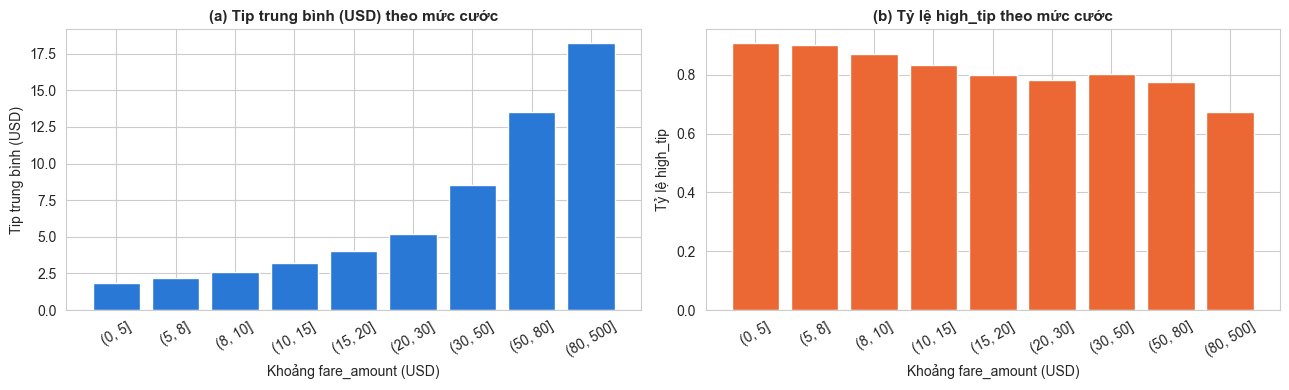

In [10]:
card_ok = trips[trips["card_ok"]]
FARE_BINS = [0, 5, 8, 10, 15, 20, 30, 50, 80, 500]
by_fare = card_ok.groupby(pd.cut(card_ok["fare_amount"], FARE_BINS), observed=True).agg(
    trips=("high_tip", "size"),
    mean_tip_usd=("tip_amount", "mean"),
    median_tip_pct=("tip_percentage", "median"),
    high_tip_rate=("high_tip", "mean"),
    zero_tip_share=("zero_tip", "mean"),
)
print(by_fare.to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
labels = [str(i) for i in by_fare.index]
axes[0].bar(labels, by_fare["mean_tip_usd"], color=C_BLUE)
axes[0].set_title("(a) Tip trung bình (USD) theo mức cước")
axes[0].set_xlabel("Khoảng fare_amount (USD)")
axes[0].set_ylabel("Tip trung bình (USD)")
axes[1].bar(labels, by_fare["high_tip_rate"], color=C_ORANGE)
axes[1].set_title("(b) Tỷ lệ high_tip theo mức cước")
axes[1].set_xlabel("Khoảng fare_amount (USD)")
axes[1].set_ylabel("Tỷ lệ high_tip")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

**Insight:** "giá cước quyết định tip" chủ yếu là hiệu ứng của cách định nghĩa nhãn, không phải khách đi chuyến rẻ hào phóng hơn.

**[BẰNG CHỨNG TỪ DỮ LIỆU]**
- Theo nhóm yếu tố: **Giá cước 0.2044** ≫ Quãng đường 0.0193 > Thời gian 0.0156 > Khu vực 0.0144 > Hành khách 0.0004. Nhóm thời gian xáo chung (0.0156) gấp đôi biến giờ mạnh nhất xáo riêng (0.0075) → kết luận "giờ không ảnh hưởng" ở Modeling bị đánh giá thấp.
- Tip **USD tăng đều** theo cước: 1.86 USD (≤ 5) → 8.51 USD (30–50) → 18.25 USD (> 80).
- Tỷ lệ **không tip** gần như phẳng **4.4–5.5%** ở mọi mức cước 5–80 USD.
- Chỉ tip % trên fare giảm (trung vị 42.7% → 20.4%) → high_tip giảm 90.9% → 67.4%.

**Tác động:** tài xế — chuyến đắt mang lại **nhiều tip USD hơn**, không ít hơn; nền tảng — không dùng `high_tip` làm KPI tip cho tài xế.

**[GIẢ THUYẾT/SUY LUẬN]** màn hình tính % trên tổng tiền gồm phụ phí cố định → chuyến rẻ dễ vượt 15% fare (bằng chứng ở H7, mục 5.4.1).

### 5.1.6. Artifact dữ liệu: chuyến thẻ `RatecodeID = 99`

Nhóm chuyến thẻ có `RatecodeID = 99` được ghi trực tiếp (không phải null được điền ở Data Preparation).

In [11]:
card = trips[trips["is_card"]]
r99_profile = card.groupby("is_r99").agg(
    trips=("high_tip", "size"),
    zero_tip_share=("zero_tip", "mean"),
    high_tip_rate=("high_tip", "mean"),
    vendor1_share=("VendorID", lambda s: (s == 1).mean()),
    mean_fare=("fare_amount", "mean"),
    mean_distance=("trip_distance", "mean"),
    mean_extra=("extra", "mean"),
    mean_improvement_surcharge=("improvement_surcharge", "mean"),
    mean_congestion_surcharge=("congestion_surcharge", "mean"),
    pickup_manhattan_share=("pickup_borough", lambda s: (s == "Manhattan").mean()),
)
r99_profile.index = ["Thẻ – RatecodeID khác 99", "Thẻ – RatecodeID = 99"]
print(r99_profile.T.to_string())
print("\nTop pickup zones of card RatecodeID=99 trips:")
print(card.loc[card["is_r99"], "pickup_zone"].value_counts().head(8).to_string())

boro = card.groupby("pickup_borough").agg(
    card_trips=("high_tip", "size"),
    r99_share=("is_r99", "mean"),
    high_tip_rate_all_card=("high_tip", "mean"),
)
boro["high_tip_rate_card_ok"] = card_ok.groupby("pickup_borough")["high_tip"].mean()
boro = boro.sort_values("card_trips", ascending=False)
print("\n", boro.to_string())

                            Thẻ – RatecodeID khác 99  Thẻ – RatecodeID = 99
trips                                 2,503,686.0000           140,071.0000
zero_tip_share                                0.0477                 1.0000
high_tip_rate                                 0.8318                 0.0000
vendor1_share                                 0.1810                 0.9998
mean_fare                                    19.4061                34.0246
mean_distance                                 3.1662                 8.3290
mean_extra                                    1.5901                 0.0000
mean_improvement_surcharge                    1.0000                 0.0002
mean_congestion_surcharge                     2.3750                 0.0005
pickup_manhattan_share                        0.9108                 0.3058

Top pickup zones of card RatecodeID=99 trips:
pickup_zone
East New York                3871
Central Harlem North         3508
Crown Heights North          3350
Eas


                 card_trips  r99_share  high_tip_rate_all_card  high_tip_rate_card_ok
pickup_borough                                                                      
Manhattan          2323300     0.0184                  0.8202                 0.8356
Queens              231011     0.0949                  0.7181                 0.7934
Brooklyn             63414     0.8473                  0.1196                 0.7833
Bronx                22052     0.9760                  0.0160                 0.6642
Unknown               3546     0.0000                  0.8212                 0.8212
Outside_NYC            374     0.1016                  0.5294                 0.5893
Staten Island           41     0.6585                  0.2195                 0.6429
EWR                     19     0.0000                  0.5789                 0.5789


                     subset      n  high_tip_rate  mean_P(high)    AUC  PR_AUC  precision_high  recall_high  recall_low  share_pred_low
Toàn bộ test (như Modeling) 528752         0.7877        0.7876 0.7164  0.8872          0.8310       0.9978      0.2471          0.0542
   Test, loại RatecodeID=99 500642         0.8319        0.8292 0.6226  0.8873          0.8325       0.9978      0.0065          0.0029
          Chỉ RatecodeID=99  28110         0.0000        0.0468 0.8624  0.0003          0.0000       0.0000      0.9676          0.9676



Low-tip lift by decile WITHOUT RatecodeID=99:
decile       1      2      3      4      5      6      7      8      9      10
rate     0.2764 0.2305 0.2088 0.1964 0.1801 0.1532 0.1362 0.1236 0.1112 0.0641
lift     1.6448 1.3717 1.2426 1.1686 1.0717 0.9117 0.8105 0.7352 0.6617 0.3816
cum_gain 0.1645 0.3016 0.4259 0.5428 0.6499 0.7411 0.8221 0.8957 0.9618 1.0000


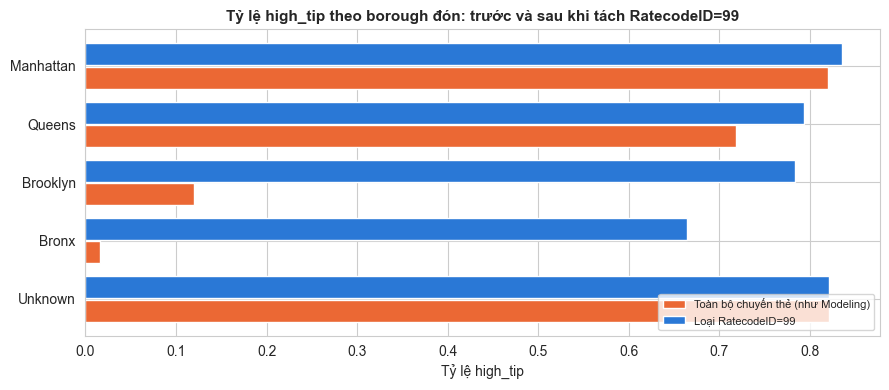

In [12]:
def subset_metrics(mask, name):
    y, p = y1_test.values[mask], p_hgb[mask]
    pred = (p >= THRESH).astype(int)
    two_classes = len(np.unique(y)) > 1
    return {"subset": name, "n": int(mask.sum()), "high_tip_rate": y.mean(), "mean_P(high)": p.mean(),
            "AUC": roc_auc_score(y, p) if two_classes else np.nan,
            "PR_AUC": average_precision_score(y, p) if two_classes else np.nan,
            "precision_high": precision_score(y, pred, pos_label=1, zero_division=0),
            "recall_high": recall_score(y, pred, pos_label=1, zero_division=0),
            "recall_low": recall_score(y, pred, pos_label=0, zero_division=0),
            "share_pred_low": 1 - pred.mean()}


model_by_subset = pd.DataFrame([
    subset_metrics(np.ones(len(y1_test), bool), "Toàn bộ test (như Modeling)"),
    subset_metrics(~r99_flag, "Test, loại RatecodeID=99"),
    subset_metrics(r99_flag, "Chỉ RatecodeID=99"),
])
print(model_by_subset.to_string(index=False))

dec_low_ok = decile_table(1 - y1_test.values[~r99_flag], 1 - p_hgb[~r99_flag])
print("\nLow-tip lift by decile WITHOUT RatecodeID=99:")
print(dec_low_ok[["rate", "lift", "cum_gain"]].T.to_string())

fig, ax = plt.subplots(figsize=(9, 4))
b = boro.loc[boro["card_trips"] >= 400]
yy = np.arange(len(b))
ax.barh(yy + 0.2, b["high_tip_rate_all_card"], height=0.38, color=C_ORANGE, label="Toàn bộ chuyến thẻ (như Modeling)")
ax.barh(yy - 0.2, b["high_tip_rate_card_ok"], height=0.38, color=C_BLUE, label="Loại RatecodeID=99")
ax.set_yticks(yy, b.index)
ax.invert_yaxis()
ax.set_title("Tỷ lệ high_tip theo borough đón: trước và sau khi tách RatecodeID=99")
ax.set_xlabel("Tỷ lệ high_tip")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

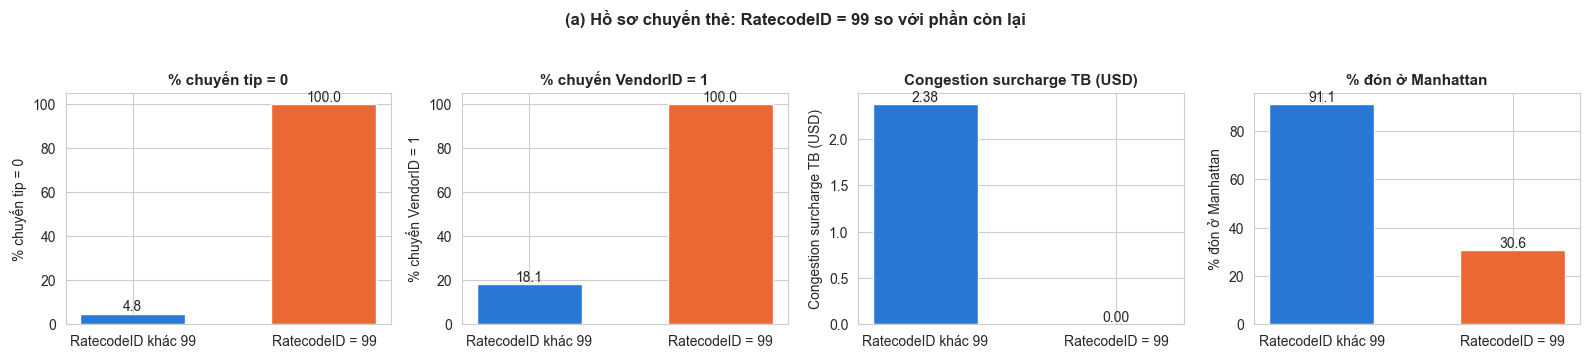

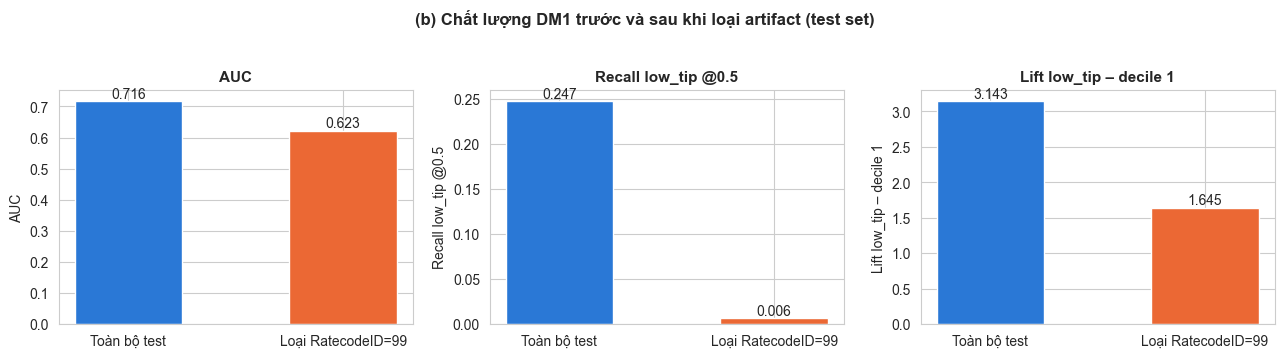

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, (col, label, scale) in zip(axes, [("zero_tip_share", "% chuyến tip = 0", 100),
                                         ("vendor1_share", "% chuyến VendorID = 1", 100),
                                         ("mean_congestion_surcharge", "Congestion surcharge TB (USD)", 1),
                                         ("pickup_manhattan_share", "% đón ở Manhattan", 100)]):
    vals = r99_profile[col].values * scale
    ax.bar(["RatecodeID khác 99", "RatecodeID = 99"], vals, color=[C_BLUE, C_ORANGE], width=0.55)
    for i, v in enumerate(vals):
        ax.text(i, v, f"{v:.1f}" if scale == 100 else f"{v:.2f}", ha="center", va="bottom")
    ax.set_title(label)
    ax.set_ylabel(label)
fig.suptitle("(a) Hồ sơ chuyến thẻ: RatecodeID = 99 so với phần còn lại", fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

model_quality = pd.DataFrame({
    "AUC": model_by_subset.loc[:1, "AUC"].values,
    "Recall low_tip @0.5": model_by_subset.loc[:1, "recall_low"].values,
    "Lift low_tip – decile 1": [dec_low_hgb.loc[1, "lift"], dec_low_ok.loc[1, "lift"]],
}, index=["Toàn bộ test", "Loại RatecodeID=99"])
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, col in zip(axes, model_quality.columns):
    ax.bar(model_quality.index, model_quality[col], color=[C_BLUE, C_ORANGE], width=0.5)
    for i, v in enumerate(model_quality[col]):
        ax.text(i, v, f"{v:.3f}", ha="center", va="bottom")
    ax.set_title(col)
    ax.set_ylabel(col)
fig.suptitle("(b) Chất lượng DM1 trước và sau khi loại artifact (test set)", fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

**Insight:** 140,071 chuyến thẻ `RatecodeID = 99` (5.3% DM1) không phải hành vi tip — đây là artifact, và nó tạo ra phần lớn "năng lực" của DM1.

**[BẰNG CHỨNG TỪ DỮ LIỆU]**
- Nhóm 99: tip = 0 ở **100.00%** chuyến (nhóm khác 4.77%), VendorID 1 **99.98%**, không phụ phí luật định (congestion TB **0.0005** vs 2.38 USD), chỉ **30.6%** đón ở Manhattan (nhóm khác 91.1%). Zone đón nhiều nhất: East New York, Central Harlem North, Crown Heights North.
- Loại nhóm 99: high_tip Bronx **1.60% → 66.42%**, Brooklyn **11.96% → 78.33%**.
- DM1 trên test đã loại nhóm 99: AUC **0.7164 → 0.6226**, recall low_tip **0.2471 → 0.0065**, lift decile 1 **3.14 → 1.64**.

**Tác động:**
- Khách: kết luận "Bronx/Brooklyn tip thấp" ở Modeling là **sai** — nếu dùng để điều phối sẽ gây thiếu xe sai chỗ cho khu dân cư (định lượng ở 5.2.2).
- Nền tảng: DM1 hiện tại học **lỗi dữ liệu**, không học hành vi khách → phải sửa Data Preparation trước khi triển khai.

**[GIẢ THUYẾT/SUY LUẬN]** tip = 0 tuyệt đối, không phụ phí, một vendor, khu dân cư → nhiều khả năng là chuyến hợp đồng/voucher ghi nhận là "thẻ"; dữ liệu không cho biết chương trình cụ thể.

### 5.1.7. DM2: các cụm có khác nhau về giá trị kinh tế không?

Fit lại KMeans (k=5 chính, k=6 so sánh) trên đúng mẫu 200k của Modeling, gán cụm cho toàn bộ chuyến, rồi đo các chỉ số **mô hình không được thấy khi phân cụm** (doanh thu, tip, sân bay).

In [14]:
DM2_COLS = list(dm2_processed.columns)
NUM_BEST = ["trip_distance", "trip_duration_min", "hour_sin", "hour_cos", "dow_sin", "dow_cos", "is_weekend"]
CAT_BEST = ["pickup_borough", "dropoff_borough"]


def add_cyclical(df: pd.DataFrame) -> pd.DataFrame:
    """Cyclical time encoding used by the DM2 best model."""
    out = df.copy()
    out["hour_sin"] = np.sin(2 * np.pi * out["pickup_hour"] / 24)
    out["hour_cos"] = np.cos(2 * np.pi * out["pickup_hour"] / 24)
    out["dow_sin"] = np.sin(2 * np.pi * out["pickup_dayofweek"] / 7)
    out["dow_cos"] = np.cos(2 * np.pi * out["pickup_dayofweek"] / 7)
    return out


samp2 = add_cyclical(trips[DM2_COLS].sample(200000, random_state=RANDOM_STATE).reset_index(drop=True))
best_pre = ColumnTransformer([("num", StandardScaler(), NUM_BEST),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_BEST)])
X2_samp = best_pre.fit_transform(samp2)
km = {k: MiniBatchKMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10, batch_size=4096).fit(X2_samp)
      for k in (5, 6)}
sil = {k: silhouette_score(X2_samp, m.labels_, sample_size=25000, random_state=RANDOM_STATE) for k, m in km.items()}
print("Silhouette (re-run):", {k: round(v, 4) for k, v in sil.items()}, "| Modeling nb: k=5 0.2054, k=6 0.2416")

X2_all = best_pre.transform(add_cyclical(trips[DM2_COLS]))
for k, m in km.items():
    trips[f"cluster_k{k}"] = m.predict(X2_all)
print("Cluster share on all trips, k=5 (%):",
      (trips["cluster_k5"].value_counts(normalize=True).sort_index() * 100).round(2).to_dict(),
      "| Modeling nb: {0: 20.34, 1: 13.69, 2: 17.83, 3: 19.47, 4: 28.67}")

Silhouette (re-run): {5: 0.2054, 6: 0.2416} | Modeling nb: k=5 0.2054, k=6 0.2416


Cluster share on all trips, k=5 (%): {0: 20.34, 1: 13.69, 2: 17.83, 3: 19.47, 4: 28.67} | Modeling nb: {0: 20.34, 1: 13.69, 2: 17.83, 3: 19.47, 4: 28.67}


In [15]:
def cluster_business_profile(df: pd.DataFrame, col: str) -> pd.DataFrame:
    """Economic profile of each cluster using columns the clustering never saw."""
    g = df.groupby(col)
    ok = df[df["card_ok"]].groupby(col)
    prof = pd.DataFrame({
        "share_trips": g.size() / len(df),
        "share_revenue": g["revenue"].sum() / df["revenue"].sum(),
        "avg_distance": g["trip_distance"].mean(),
        "avg_duration": g["trip_duration_min"].mean(),
        "avg_pickup_hour": g["pickup_hour"].mean(),
        "weekend_share": g["is_weekend"].mean(),
        "revenue_per_trip": g["revenue"].mean(),
        "revenue_per_occ_hour": g["revenue"].sum() / g["trip_duration_min"].sum() * 60,
        "airport_share": g["is_airport"].mean(),
        "airport_fee_share": g["has_airport_fee"].mean(),
        "cash_share": g["is_cash"].mean(),
        "high_tip_rate_card_ok": ok["high_tip"].mean(),
        "avg_tip_usd_card_ok": ok["tip_amount"].mean(),
    })
    prof["top_pickup_zones"] = g["pickup_zone"].agg(lambda s: ", ".join(s.value_counts().index[:3]))
    return prof


prof_k5 = cluster_business_profile(trips, "cluster_k5")
prof_k6 = cluster_business_profile(trips, "cluster_k6")
print("k=5:\n", prof_k5.drop(columns="top_pickup_zones").to_string())
print("\n", prof_k5["top_pickup_zones"].to_string())
print("\nk=6:\n", prof_k6.drop(columns="top_pickup_zones").to_string())

k=5:
             share_trips  share_revenue  avg_distance  avg_duration  avg_pickup_hour  weekend_share  revenue_per_trip  revenue_per_occ_hour  airport_share  airport_fee_share  cash_share  high_tip_rate_card_ok  avg_tip_usd_card_ok
cluster_k5                                                                                                                                                                                                                          
0                0.2034         0.1650        2.3463       14.1986          17.7665         0.0000           19.8075               83.7018         0.0334             0.0328      0.0884                 0.8508               3.7942
1                0.1369         0.1179        2.9592       15.6571          12.1120         1.0000           21.0371               80.6170         0.0574             0.0370      0.1032                 0.8391               3.8698
2                0.1783         0.1811        3.8879       17.9910          14

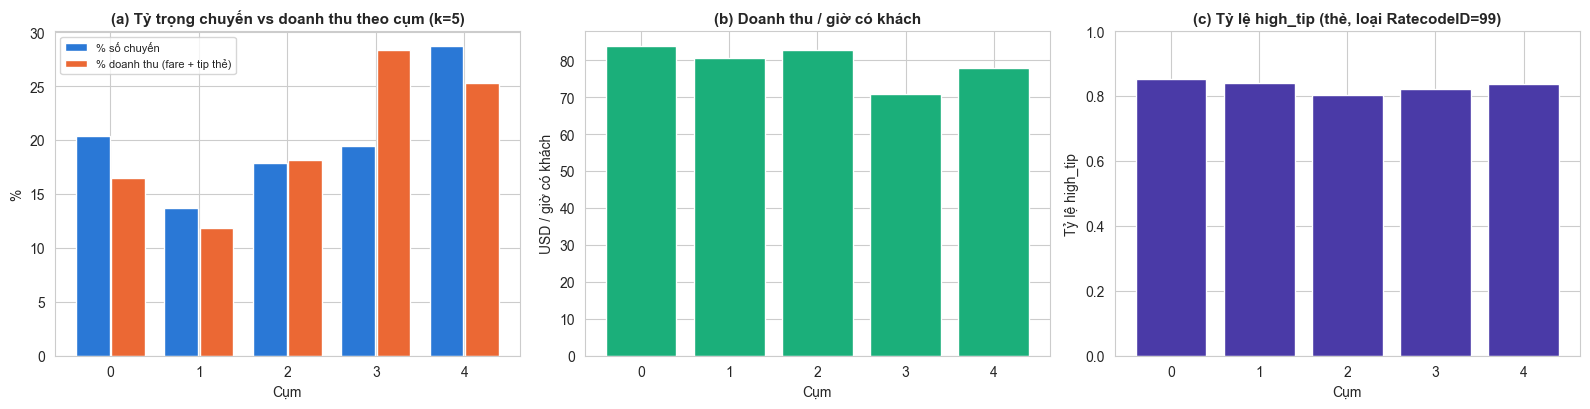

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
x = np.arange(len(prof_k5))
ax = axes[0]
ax.bar(x - 0.2, prof_k5["share_trips"] * 100, width=0.38, color=C_BLUE, label="% số chuyến")
ax.bar(x + 0.2, prof_k5["share_revenue"] * 100, width=0.38, color=C_ORANGE, label="% doanh thu (fare + tip thẻ)")
ax.set_title("(a) Tỷ trọng chuyến vs doanh thu theo cụm (k=5)")
ax.set_xlabel("Cụm")
ax.set_ylabel("%")
ax.set_xticks(x)
ax.legend(fontsize=8)

axes[1].bar(x, prof_k5["revenue_per_occ_hour"], color=C_AQUA)
axes[1].set_title("(b) Doanh thu / giờ có khách")
axes[1].set_xlabel("Cụm")
axes[1].set_ylabel("USD / giờ có khách")
axes[1].set_xticks(x)

axes[2].bar(x, prof_k5["high_tip_rate_card_ok"], color=C_VIOLET)
axes[2].set_title("(c) Tỷ lệ high_tip (thẻ, loại RatecodeID=99)")
axes[2].set_xlabel("Cụm")
axes[2].set_ylabel("Tỷ lệ high_tip")
axes[2].set_xticks(x)
axes[2].set_ylim(0, 1)
plt.tight_layout()
plt.show()

**Insight:** các cụm DM2 khác nhau rõ về **giá trị kinh tế** (dù model không thấy biến giá) nhưng **không** khác nhau về tip → DM2 hữu ích cho điều phối, không cho dự đoán tip.

**[BẰNG CHỨNG TỪ DỮ LIỆU]** (tái tạo khớp: Silhouette k=5 0.2054, tỷ trọng cụm trùng Modeling)

| Cụm (k=5) | % chuyến | % doanh thu | USD/giờ có khách | % chạm sân bay | high_tip | Tip TB |
|---|---|---|---|---|---|---|
| 0 – Tan tầm ngày thường | 20.34 | 16.50 | **83.70** | 3.3 | 0.851 | 3.79 |
| 1 – Trưa cuối tuần | 13.69 | 11.79 | 80.62 | 5.7 | 0.839 | 3.87 |
| 2 – Trung bình cuối tuần | 17.83 | 18.11 | 82.77 | 8.4 | 0.802 | 4.52 |
| 3 – Dài/liên borough ngày thường | 19.47 | **28.32** | **70.78** | 19.2 | 0.823 | **6.60** |
| 4 – Ngắn điển hình ngày thường | 28.67 | 25.27 | 77.83 | 4.4 | 0.836 | 4.02 |

- high_tip chỉ dao động **0.80–0.85** giữa các cụm.
- k=6 tách cụm sân bay: **8.52%** chuyến, **23.87%** doanh thu, 60.5% chạm sân bay, tip TB 13.65 USD.
- Silhouette 0.2054 **chưa đạt** ngưỡng 0.3.

**Tác động:** nền tảng — cụm 3 mang nhiều tiền/chuyến nhưng năng suất giờ thấp nhất → cần chính sách riêng (5.2.3); tài xế — chuyến ngắn tan tầm cho năng suất giờ cao nhất.

## 5.2. Tác động business của model

### 5.2.1. Tài xế: làm theo DM1 có kiếm thêm tiền không? (backtest)

5 chiến lược chọn ô *zone × khung giờ*. Điểm của mỗi ô tính trên **tập train**, kết quả đo trên **chuyến thật của tập test** (`card_ok`). Chọn top 20% ô theo điểm. Giới hạn: train/test cùng tháng (không phải kiểm định theo thời gian).

In [17]:
TOP_SHARE, MIN_TRAIN_CELL = 0.20, 200
CELL = ["PULocationID", "slot"]
train_meta = dm1.loc[idx_train].copy()
train_meta["p_hgb"] = hgb.predict_proba(X1_train_enc)[:, 1]


def in_scope(df):
    return df[df["pu_in_month"] & ~df["PULocationID"].isin(UNKNOWN_ZONE_IDS)]


def cell_table(df):
    # per zone x slot: size, DM1 score and historical KPIs
    g = df.groupby(CELL)
    return pd.DataFrame({"n": g.size(), "borough": g["pickup_borough"].first(), "zone": g["pickup_zone"].first(),
                         "dm1_score": g["p_hgb"].mean(), "high_tip": g["high_tip"].mean(),
                         "tip_usd": g["tip_amount"].mean(),
                         "rev_per_occ_hour": g["revenue"].sum() / g["trip_duration_min"].sum() * 60})


def top_cells(score):
    return set(score[score >= score.quantile(1 - TOP_SHARE)].index)


tr_ok = cell_table(in_scope(train_meta[train_meta["card_ok"]]))
tr_ok = tr_ok[tr_ok["n"] >= MIN_TRAIN_CELL]
te_ok = in_scope(test_meta[test_meta["card_ok"]])
te_key = pd.MultiIndex.from_frame(te_ok[CELL])

STRATEGIES = {
    "Hiện trạng (mọi ô)": set(tr_ok.index),
    "Kinh nghiệm: chỉ chạy Manhattan": set(tr_ok.index[tr_ok["borough"] == "Manhattan"]),
    "DM1: top 20% P(high_tip)": top_cells(tr_ok["dm1_score"]),
    "Lịch sử: top 20% tip USD": top_cells(tr_ok["tip_usd"]),
    "Lịch sử: top 20% thu nhập/giờ": top_cells(tr_ok["rev_per_occ_hour"]),
}
rows = []
for name, cells_ in STRATEGIES.items():
    m = te_key.isin(list(cells_))
    s = te_ok[m]
    rows.append({"strategy": name, "cells": len(cells_), "share_of_test_trips": m.mean(),
                 "rev_per_occ_hour": s["revenue"].sum() / s["trip_duration_min"].sum() * 60,
                 "tip_usd_per_trip": s["tip_amount"].mean(), "high_tip_rate": s["high_tip"].mean(),
                 "rev_per_trip": s["revenue"].mean(), "airport_share": s["is_airport"].mean()})
backtest = pd.DataFrame(rows).set_index("strategy")
status_quo = backtest.loc["Hiện trạng (mọi ô)"]
backtest["delta_rev_per_occ_hour"] = backtest["rev_per_occ_hour"] - status_quo["rev_per_occ_hour"]
backtest["delta_usd_per_shift"] = backtest["delta_rev_per_occ_hour"] * SHIFT_H * UTIL
backtest["delta_tip_usd_per_trip"] = backtest["tip_usd_per_trip"] - status_quo["tip_usd_per_trip"]
print(f"Cells scored on train: {len(tr_ok)} | test card_ok trips in scope: {len(te_ok):,}")
print(backtest.to_string())

rho_tip, _ = spearmanr(tr_ok["dm1_score"], tr_ok["tip_usd"])
rho_rev, _ = spearmanr(tr_ok["dm1_score"], tr_ok["rev_per_occ_hour"])
print(f"\nSpearman over cells: DM1 score vs tip USD = {rho_tip:.4f} | DM1 score vs revenue/occupied hour = {rho_rev:.4f}")

Cells scored on train: 437 | test card_ok trips in scope: 499,905
                                 cells  share_of_test_trips  rev_per_occ_hour  tip_usd_per_trip  high_tip_rate  rev_per_trip  airport_share  delta_rev_per_occ_hour  delta_usd_per_shift  delta_tip_usd_per_trip
strategy                                                                                                                                                                                                        
Hiện trạng (mọi ô)                 437               0.9892           82.8715            4.4691         0.8328       23.6588         0.0966                  0.0000               0.0000                  0.0000
Kinh nghiệm: chỉ chạy Manhattan    407               0.9092           79.3750            3.8071         0.8361       19.6828         0.0207                 -3.4965             -16.7831                 -0.6619
DM1: top 20% P(high_tip)            88               0.3028           80.2074            3.9876   

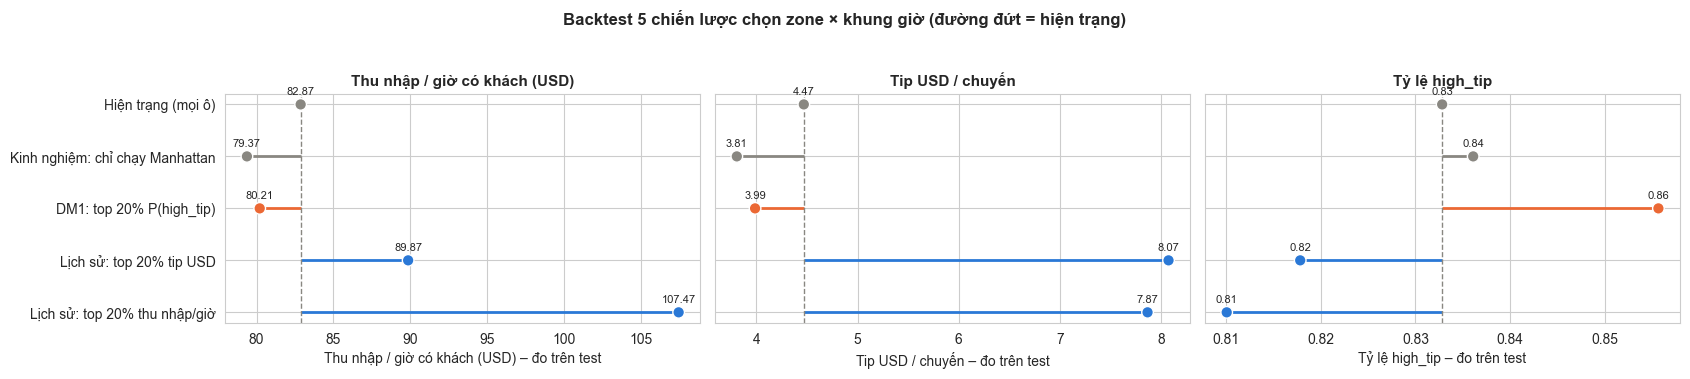

In [18]:
colors = [C_GREY, C_GREY, C_ORANGE, C_BLUE, C_BLUE]
y = np.arange(len(backtest))
fig, axes = plt.subplots(1, 3, figsize=(17, 3.6))
for k, (ax, (col, label)) in enumerate(zip(axes, [("rev_per_occ_hour", "Thu nhập / giờ có khách (USD)"),
                                                 ("tip_usd_per_trip", "Tip USD / chuyến"),
                                                 ("high_tip_rate", "Tỷ lệ high_tip")])):
    ax.hlines(y, status_quo[col], backtest[col], color=colors, lw=2)
    ax.scatter(backtest[col], y, color=colors, s=70, zorder=3, edgecolor="white")
    ax.axvline(status_quo[col], ls="--", lw=1, color=C_GREY)
    for yi, v in zip(y, backtest[col]):
        ax.annotate(f"{v:.2f}", (v, yi), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8)
    ax.set_yticks(y, backtest.index if k == 0 else [""] * len(y))
    ax.invert_yaxis()
    ax.set_title(label)
    ax.set_xlabel(label + " – đo trên test")
fig.suptitle("Backtest 5 chiến lược chọn zone × khung giờ (đường đứt = hiện trạng)", fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

**Insight:** điểm DM1 dẫn tài xế tới chuyến **ngắn, rẻ, tip % cao nhưng tip USD thấp** → thu nhập giảm. Thống kê lịch sử đơn giản (tip USD, thu nhập/giờ) cho kết quả tốt hơn model.

**[BẰNG CHỨNG TỪ DỮ LIỆU]** (437 ô chấm điểm trên train; 499,905 chuyến test `card_ok`)

| Chiến lược | % chuyến test khả dụng | USD/giờ có khách | Δ vs hiện trạng | Tip USD/chuyến | high_tip |
|---|---|---|---|---|---|
| Hiện trạng (mọi ô) | 98.9% | 82.87 | – | 4.47 | 0.833 |
| Kinh nghiệm: chỉ Manhattan | 90.9% | 79.37 | **−3.50** | 3.81 | 0.836 |
| **DM1: top 20%** | 30.3% | 80.21 | **−2.66** (≈ −12.79 USD/ca) | **3.99** | **0.856** |
| Lịch sử: top 20% tip USD | 17.5% | 89.87 | **+7.00** | 8.07 | 0.818 |
| Lịch sử: top 20% thu nhập/giờ | 8.7% | 107.47 | **+24.60** | 7.87 | 0.810 |

- DM1 **đúng mục tiêu của nó** (high_tip 0.856, cao nhất) nhưng **ngược KPI tài xế**: Spearman điểm DM1 vs tip USD = **−0.41**, vs thu nhập/giờ = **−0.21**.
- Hai chiến lược lịch sử thắng nhờ sân bay/chuyến dài (**47–51%** chuyến chạm sân bay) và chỉ chứa **8.7–17.5%** chuyến → không phải mọi tài xế cùng làm được.

**[GIẢ THUYẾT/SUY LUẬN]** "USD/giờ có khách" chưa trừ thời gian xếp hàng ở sân bay → lợi ích của hai chiến lược lịch sử bị **phóng đại**; với DM1 kết luận không đổi vì DM1 thua ngay cả khi chưa tính thời gian chờ.

**Tác động:** tài xế — làm theo DM1 mất ~**12.8 USD/ca**; nền tảng — không triển khai DM1 làm công cụ gợi ý thu nhập; dùng bảng KPI lịch sử + A/B test.

### 5.2.2. Khách hàng: nếu tài xế né các ô bị DM1 chấm thấp, ai bị ảnh hưởng?

Giả lập tài xế tránh 20% ô có điểm DM1 thấp nhất. So sánh điểm DM1 tính **trên mọi chuyến thẻ (như model được huấn luyện, gồm artifact)** với điểm **đã loại RatecodeID = 99**. Đo số chuyến/ngày (mọi hình thức thanh toán) nằm trong các ô bị né.


Điểm DM1 gồm RatecodeID=99 - top zones by affected trips/day:
pickup_zone
Central Harlem North        359.7000
Crown Heights North         185.5000
Washington Heights South    173.2000
East New York               143.9000
Hamilton Heights            119.6000
Prospect-Lefferts Gardens    80.6000



Điểm DM1 đã loại RatecodeID=99 - top zones by affected trips/day:
pickup_zone
JFK Airport                    4,532.8000
East Village                   1,089.4000
West Village                     781.5000
Financial District North         728.1000
Lower East Side                  689.6000
Penn Station/Madison Sq West     633.3000

                                 cells_avoided  trips_per_day  share_of_all_trips  share_outside_manhattan  share_cash_or_unreported  airport_share
scenario                                                                                                                                          
Điểm DM1 gồm RatecodeID=99                113     2,784.9355              0.0222                   0.7338                    0.4128         0.0152
Điểm DM1 đã loại RatecodeID=99             88    17,922.8387              0.1431                   0.2795                    0.3774         0.2632


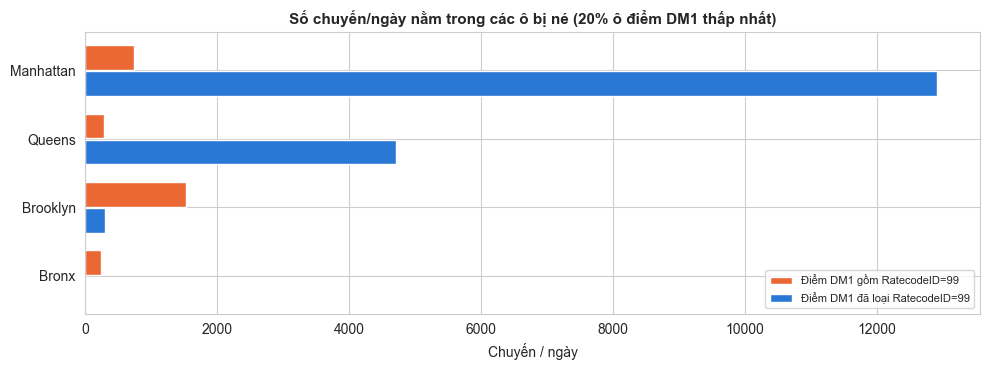

In [19]:
tr_card = cell_table(in_scope(train_meta))          # all card trips, as DM1 was trained
tr_card = tr_card[tr_card["n"] >= MIN_TRAIN_CELL]


def bottom_cells(score):
    return set(score[score <= score.quantile(TOP_SHARE)].index)


AVOID = {"Điểm DM1 gồm RatecodeID=99": bottom_cells(tr_card["dm1_score"]),
         "Điểm DM1 đã loại RatecodeID=99": bottom_cells(tr_ok["dm1_score"])}
zs_key = pd.MultiIndex.from_frame(zone_src[CELL])
rows, by_boro = [], {}
for name, cells_ in AVOID.items():
    m = zs_key.isin(list(cells_))
    s = zone_src[m]
    rows.append({"scenario": name, "cells_avoided": len(cells_), "trips_per_day": m.sum() / N_DAYS,
                 "share_of_all_trips": m.mean(),
                 "share_outside_manhattan": (s["pickup_borough"] != "Manhattan").mean(),
                 "share_cash_or_unreported": (s["is_cash"] | (s["payment_type"] == 0)).mean(),
                 "airport_share": s["is_airport"].mean()})
    by_boro[name] = s.groupby("pickup_borough").size() / N_DAYS
    print(f"\n{name} - top zones by affected trips/day:")
    print((s.groupby("pickup_zone").size() / N_DAYS).nlargest(6).round(1).to_string())
avoid_tbl = pd.DataFrame(rows).set_index("scenario")
print("\n", avoid_tbl.to_string())

boro_avoid = pd.DataFrame(by_boro).fillna(0)
boro_avoid = boro_avoid.loc[boro_avoid.max(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(10, 3.8))
yy = np.arange(len(boro_avoid))
for i, (name, c) in enumerate(zip(boro_avoid.columns, [C_ORANGE, C_BLUE])):
    ax.barh(yy + (i - 0.5) * 0.38, boro_avoid[name], height=0.36, color=c, label=name)
ax.set_yticks(yy, boro_avoid.index)
ax.invert_yaxis()
ax.set_title("Số chuyến/ngày nằm trong các ô bị né (20% ô điểm DM1 thấp nhất)")
ax.set_xlabel("Chuyến / ngày")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Insight:** dùng DM1 chưa sửa artifact để điều phối sẽ **rút xe khỏi khu dân cư ngoài Manhattan**; DM1 đã sửa thì rút xe khỏi **sân bay và khu ăn chơi** — đều là quyết định sai.

**[BẰNG CHỨNG TỪ DỮ LIỆU]**

| Điểm dùng để né | Ô bị né | Chuyến/ngày bị ảnh hưởng | % tổng chuyến | % ngoài Manhattan | % tiền mặt / không báo | Zone bị ảnh hưởng nhiều nhất |
|---|---|---|---|---|---|---|
| DM1 gồm RatecodeID = 99 | 113 | **2,785** | 2.2% | **73.4%** | 41.3% | Central Harlem North (360/ngày), Crown Heights North (186), Washington Heights South (173), East New York (144) |
| DM1 đã loại RatecodeID = 99 | 88 | **17,923** | **14.3%** | 28.0% | 37.7% | JFK (4,533/ngày), East Village (1,089), West Village (782), Financial District North (728) |

**Tác động:**
- Khách: kịch bản 1 làm giảm cung xe cho khu dân cư Harlem/Brooklyn chỉ vì **lỗi dữ liệu**; kịch bản 2 né JFK — nơi có tip USD cao nhất (12.88 USD).
- Nền tảng: **[GIẢ THUYẾT/SUY LUẬN]** gợi ý né khu vực theo "khả năng tip" là rủi ro công bằng dịch vụ; quy định TLC cấm taxi từ chối chở khách theo điểm đến → model chỉ nên dùng để **bổ sung** xe, không để rút xe.

### 5.2.3. Điều phối: chi phí cơ hội của từng cụm DM2 (k=6)

Airport cluster (k=6): 2 | trips: 330,971 | reference revenue/occupied hour of other clusters: 78.91 USD
            share_trips  share_revenue  revenue_per_trip  avg_duration  revenue_per_occ_hour  airport_share  avg_tip_usd_card_ok  opportunity_cost_per_trip
cluster_k6                                                                                                                                                 
0                0.1475         0.1253           20.7453       15.1632               82.0880         0.0354               3.6857                    -0.8036
1                0.2540         0.2126           20.4440       15.4929               79.1743         0.0246               3.8367                    -0.0687
2                0.0852         0.2387           68.4446       55.4536               74.0561         0.6052              13.6488                     4.4845
3                0.1514         0.1239           19.9810       15.2493               78.6175         0.0404        

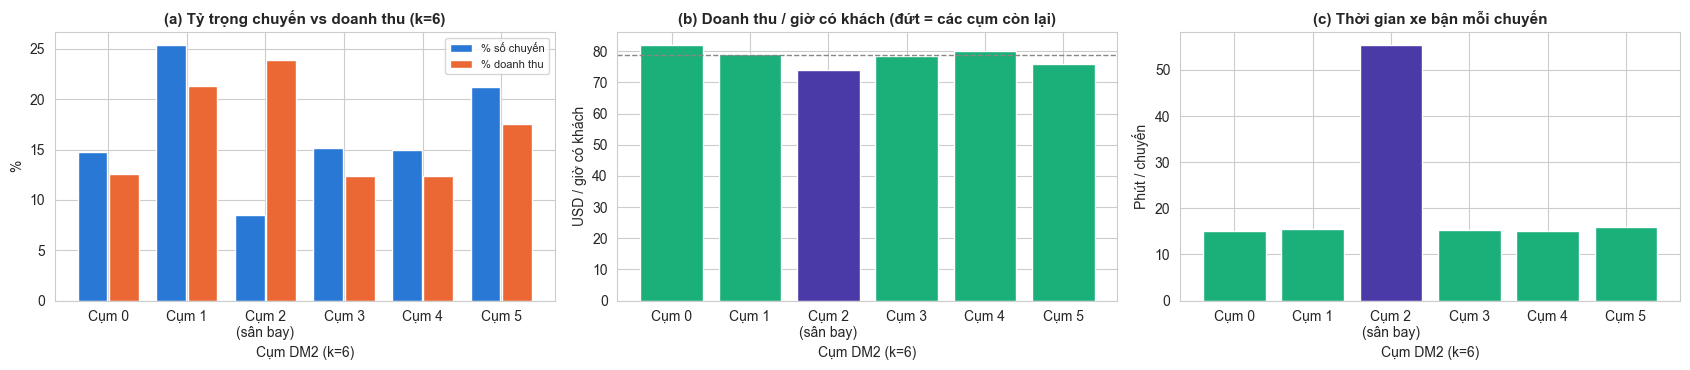

In [20]:
airport_cluster = prof_k6["airport_share"].idxmax()
rest = trips[trips["cluster_k6"] != airport_cluster]
ref_rate = rest["revenue"].sum() / rest["trip_duration_min"].sum() * 60
# [assumption] the same occupied minutes could have been spent on non-airport trips at ref_rate
prof_k6["opportunity_cost_per_trip"] = (ref_rate - prof_k6["revenue_per_occ_hour"]) * prof_k6["avg_duration"] / 60
n_airport = int((trips["cluster_k6"] == airport_cluster).sum())
print(f"Airport cluster (k=6): {airport_cluster} | trips: {n_airport:,} | "
      f"reference revenue/occupied hour of other clusters: {ref_rate:.2f} USD")
print(prof_k6[["share_trips", "share_revenue", "revenue_per_trip", "avg_duration", "revenue_per_occ_hour",
               "airport_share", "avg_tip_usd_card_ok", "opportunity_cost_per_trip"]].to_string())
print(f"Monthly occupied-time opportunity cost of airport cluster: "
      f"{prof_k6.loc[airport_cluster, 'opportunity_cost_per_trip'] * n_airport:,.0f} USD")

labels = [f"Cụm {i}\n(sân bay)" if i == airport_cluster else f"Cụm {i}" for i in prof_k6.index]
x = np.arange(len(prof_k6))
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
axes[0].bar(x - 0.2, prof_k6["share_trips"] * 100, width=0.38, color=C_BLUE, label="% số chuyến")
axes[0].bar(x + 0.2, prof_k6["share_revenue"] * 100, width=0.38, color=C_ORANGE, label="% doanh thu")
axes[0].set_title("(a) Tỷ trọng chuyến vs doanh thu (k=6)")
axes[0].set_ylabel("%")
axes[0].legend(fontsize=8)
axes[1].bar(x, prof_k6["revenue_per_occ_hour"], color=[C_VIOLET if i == airport_cluster else C_AQUA for i in prof_k6.index])
axes[1].axhline(ref_rate, ls="--", lw=1, color=C_GREY)
axes[1].set_title("(b) Doanh thu / giờ có khách (đứt = các cụm còn lại)")
axes[1].set_ylabel("USD / giờ có khách")
axes[2].bar(x, prof_k6["avg_duration"], color=[C_VIOLET if i == airport_cluster else C_AQUA for i in prof_k6.index])
axes[2].set_title("(c) Thời gian xe bận mỗi chuyến")
axes[2].set_ylabel("Phút / chuyến")
for ax in axes:
    ax.set_xticks(x, labels)
    ax.set_xlabel("Cụm DM2 (k=6)")
plt.tight_layout()
plt.show()

**Insight:** chuyến sân bay mang về nhiều tiền mỗi chuyến nhưng giữ xe lâu, năng suất mỗi giờ có khách thấp hơn → cần lịch điều phối riêng.

**[BẰNG CHỨNG TỪ DỮ LIỆU]**
- Cụm 2 (sân bay, k=6): **330,971** chuyến (8.5%), **23.9%** doanh thu, **68.44 USD**/chuyến, tip TB **13.65 USD**, xe bận **55.5 phút**/chuyến.
- Năng suất **74.06 USD/giờ có khách** vs **78.91** của các cụm còn lại (−6.1%).
- **[GIẢ ĐỊNH KỊCH BẢN]** nếu cùng thời gian có khách dùng cho chuyến nội đô: chi phí cơ hội **4.48 USD/chuyến sân bay** ≈ **1.48 triệu USD/tháng**.

**[GIẢ THUYẾT/SUY LUẬN]** phép so sánh chỉ tính thời gian có khách: chuyến nội đô cần ~3 lần đón khách để bằng doanh thu 1 chuyến sân bay (mỗi lần đón có thời gian chờ), còn sân bay có thời gian xếp hàng — dữ liệu không đo được cả hai.

**Tác động:** nền tảng — tách lịch riêng cho cụm sân bay (k=6), không áp chung quy tắc với 5 cụm nội đô; tài xế — chuyến sân bay chỉ đáng khi thời gian xếp hàng ngắn.

## 5.3. Phân tích theo khu vực (zone/borough) và khung giờ

Chỉ số theo **zone đón**, giờ đón trong 05/2026: `trips_per_day`, `revenue_per_trip` (fare + tip, mọi thanh toán), `high_tip_rate` / `avg_tip_usd` / `tip_pct_of_fare` (= Σtip ÷ Σfare) trên `card_ok`, `cash_share`. Khung giờ = `time_of_day` × ngày thường/cuối tuần (8 khung). Ngưỡng ổn định: zone ≥ 500, ô zone × khung giờ ≥ 100 chuyến `card_ok`.

In [21]:
zone_src = trips[trips["pu_in_month"] & ~trips["PULocationID"].isin(UNKNOWN_ZONE_IDS)]
N_DAYS = 31
MIN_CARD_ZONE, MIN_CARD_CELL = 500, 100
ZONE_KEYS = ["PULocationID", "pickup_borough", "pickup_zone"]


def zone_metrics(df: pd.DataFrame, keys: list) -> pd.DataFrame:
    """Volume, revenue and tip metrics per group of pickup zone (and optionally slot)."""
    g = df.groupby(keys, observed=True)
    ok = df[df["card_ok"]].groupby(keys, observed=True)
    out = pd.DataFrame({
        "trips": g.size(),
        "revenue_per_trip": g["revenue"].mean(),
        "fare_per_trip": g["fare_amount"].mean(),
        "avg_distance": g["trip_distance"].mean(),
        "avg_duration": g["trip_duration_min"].mean(),
        "revenue_per_occ_hour": g["revenue"].sum() / g["trip_duration_min"].sum() * 60,
        "cash_share": g["is_cash"].mean(),
        "airport_share": g["is_airport"].mean(),
        "airport_fee_share": g["has_airport_fee"].mean(),
        "r99_share_of_card": g["is_r99"].sum() / g["is_card"].sum().replace(0, np.nan),
        "card_ok_trips": ok.size(),
        "high_tip_rate": ok["high_tip"].mean(),
        "avg_tip_usd": ok["tip_amount"].mean(),
        "tip_pct_of_fare": ok["tip_amount"].sum() / ok["fare_amount"].sum(),
        "zero_tip_share": ok["zero_tip"].mean(),
    })
    out["card_ok_trips"] = out["card_ok_trips"].fillna(0).astype(int)
    return out


slot_tbl = zone_metrics(zone_src, ["slot"]).reindex(SLOT_ORDER)
print("By slot (all zones):")
print(slot_tbl[["trips", "revenue_per_trip", "high_tip_rate", "avg_tip_usd", "tip_pct_of_fare", "cash_share"]].to_string())

zone_tbl = zone_metrics(zone_src, ZONE_KEYS).reset_index()
zone_tbl["trips_per_day"] = zone_tbl["trips"] / N_DAYS
zone_elig = zone_tbl[zone_tbl["card_ok_trips"] >= MIN_CARD_ZONE].copy()
print(f"\nZones total: {len(zone_tbl)} | eligible (>= {MIN_CARD_ZONE} card_ok trips): {len(zone_elig)} "
      f"covering {zone_elig['trips'].sum() / zone_tbl['trips'].sum():.2%} of trips")

cell_tbl = zone_metrics(zone_src, ZONE_KEYS + ["slot"]).reset_index()
cell_elig = cell_tbl[cell_tbl["card_ok_trips"] >= MIN_CARD_CELL].copy()
print(f"Zone x slot cells: {len(cell_tbl)} | eligible (>= {MIN_CARD_CELL} card_ok trips): {len(cell_elig)}")

show_cols = ["pickup_borough", "pickup_zone", "trips_per_day", "revenue_per_trip", "high_tip_rate",
             "avg_tip_usd", "tip_pct_of_fare", "cash_share"]
print("\nTop 10 zones by trip volume:")
print(zone_elig.nlargest(10, "trips")[show_cols].to_string(index=False))

By slot (all zones):
                        trips  revenue_per_trip  high_tip_rate  avg_tip_usd  tip_pct_of_fare  cash_share
slot                                                                                                    
weekday|early_morning  410629           24.5529         0.8259       4.1476           0.2290      0.0689
weekday|midday         838997           25.7431         0.8429       4.7531           0.2291      0.1111
weekday|peak_hour      647087           23.9350         0.8437       4.6656           0.2473      0.0920
weekday|late_night     754006           24.6751         0.8305       4.4966           0.2317      0.0758
weekend|early_morning   95247           23.4640         0.8369       4.3185           0.2281      0.1125
weekend|midday         388557           23.8340         0.8360       4.3775           0.2271      0.1006
weekend|peak_hour      296181           23.9110         0.8257       4.3855           0.2227      0.0955
weekend|late_night     451024     


Zones total: 257 | eligible (>= 500 card_ok trips): 75 covering 94.85% of trips


Zone x slot cells: 1991 | eligible (>= 100 card_ok trips): 530

Top 10 zones by trip volume:
pickup_borough                  pickup_zone  trips_per_day  revenue_per_trip  high_tip_rate  avg_tip_usd  tip_pct_of_fare  cash_share
     Manhattan        Upper East Side South     6,122.2581           17.2020         0.8635       3.3733           0.2497      0.0985
     Manhattan        Upper East Side North     5,402.5484           17.7308         0.8602       3.3598           0.2458      0.0835
     Manhattan               Midtown Center     4,986.0000           21.7969         0.8445       4.1826           0.2432      0.1010
        Queens                  JFK Airport     4,532.8387           71.3447         0.7394      12.8825           0.1919      0.2672
     Manhattan          Lincoln Square East     3,844.4839           18.8484         0.8612       3.6543           0.2499      0.0994
     Manhattan                 Midtown East     3,728.7419           20.7574         0.8432       4.020

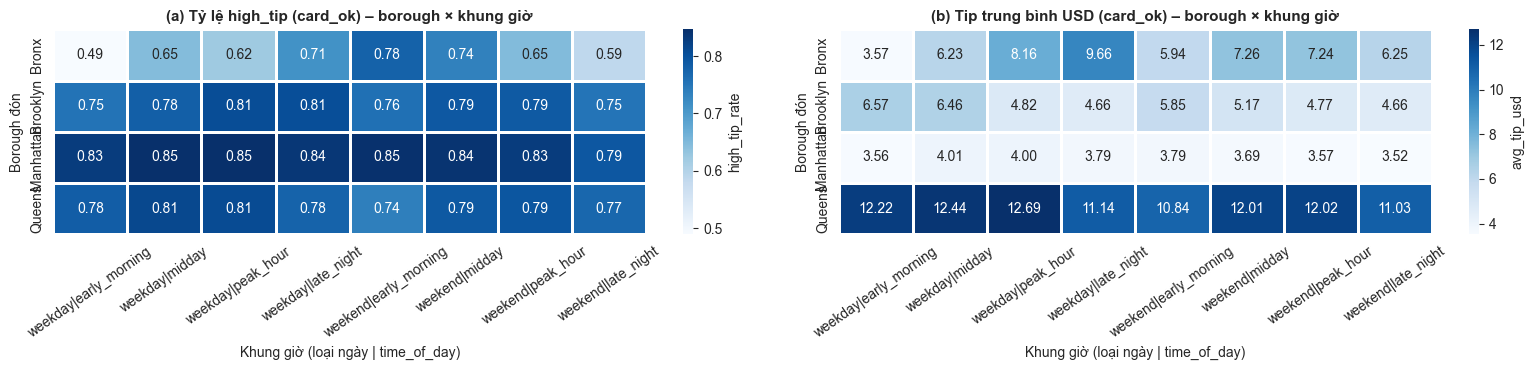

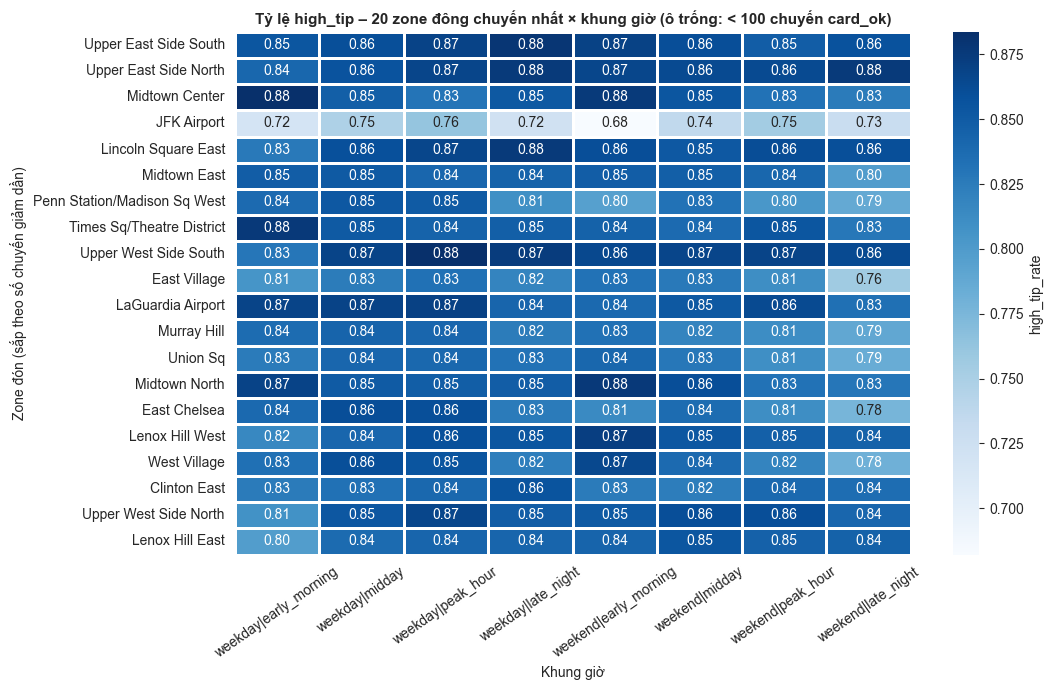

In [22]:
boro_slot = zone_metrics(zone_src[zone_src["pickup_borough"].isin(["Manhattan", "Queens", "Brooklyn", "Bronx"])],
                         ["pickup_borough", "slot"]).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(16, 3.8))
for ax, metric, title, fmt in [(axes[0], "high_tip_rate", "(a) Tỷ lệ high_tip (card_ok)", ".2f"),
                               (axes[1], "avg_tip_usd", "(b) Tip trung bình USD (card_ok)", ".2f")]:
    pv = boro_slot.pivot(index="pickup_borough", columns="slot", values=metric)[SLOT_ORDER]
    sns.heatmap(pv, annot=True, fmt=fmt, cmap="Blues", cbar_kws={"label": metric}, ax=ax,
                linewidths=2, linecolor="white")
    ax.set_title(title + " – borough × khung giờ")
    ax.set_xlabel("Khung giờ (loại ngày | time_of_day)")
    ax.set_ylabel("Borough đón")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

top20 = zone_elig.nlargest(20, "trips")["PULocationID"]
pv = (cell_tbl[cell_tbl["PULocationID"].isin(top20) & (cell_tbl["card_ok_trips"] >= MIN_CARD_CELL)]
      .pivot(index="pickup_zone", columns="slot", values="high_tip_rate")
      .reindex(columns=SLOT_ORDER))
pv = pv.loc[zone_elig.set_index("pickup_zone").loc[pv.index, "trips"].sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(11, 7))
sns.heatmap(pv, annot=True, fmt=".2f", cmap="Blues", cbar_kws={"label": "high_tip_rate"}, ax=ax,
            linewidths=1, linecolor="white")
ax.set_title("Tỷ lệ high_tip – 20 zone đông chuyến nhất × khung giờ (ô trống: < 100 chuyến card_ok)")
ax.set_xlabel("Khung giờ")
ax.set_ylabel("Zone đón (sắp theo số chuyến giảm dần)")
ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

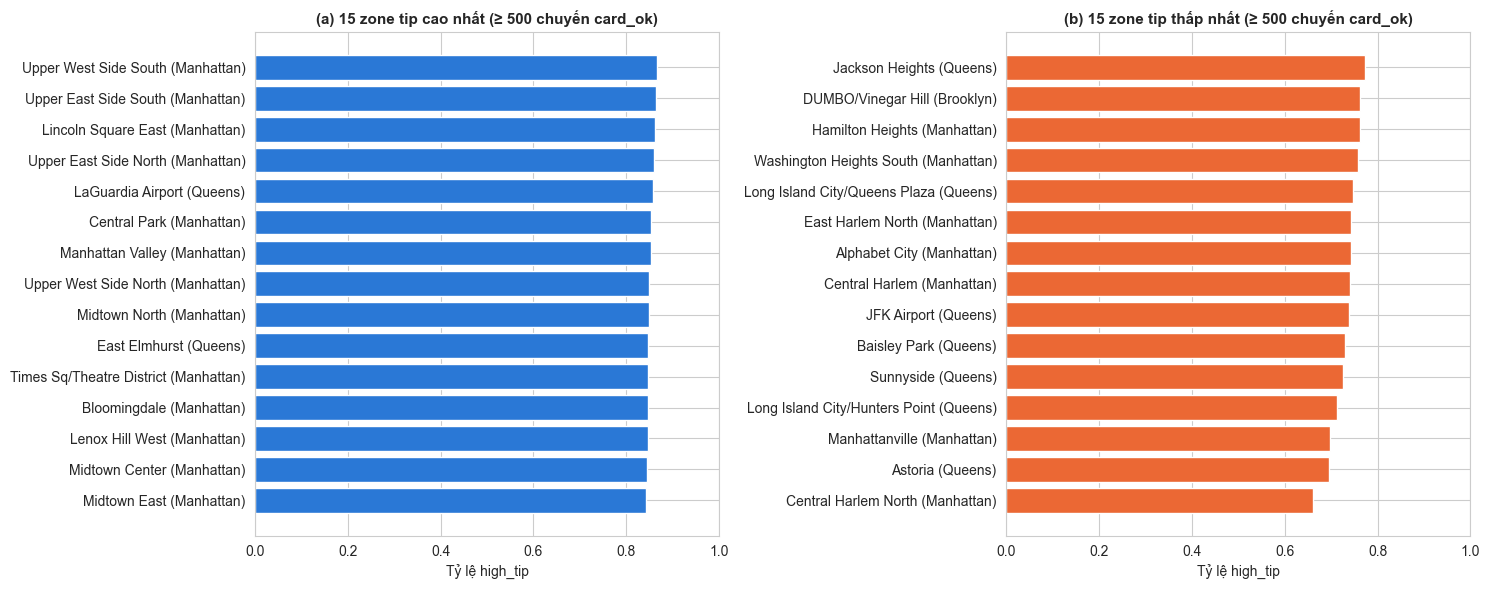

pickup_borough                    pickup_zone  trips_per_day  revenue_per_trip  high_tip_rate  avg_tip_usd  tip_pct_of_fare  cash_share  card_ok_trips
     Manhattan           Central Harlem North       458.3871           25.7568         0.6610       3.2675           0.1890      0.0576            935
        Queens                        Astoria       236.1935           28.6001         0.6948       4.8865           0.1932      0.0649            616
     Manhattan                 Manhattanville       194.3871           24.9602         0.6975       3.4595           0.1894      0.0632           1005
        Queens Long Island City/Hunters Point       245.2581           34.3794         0.7129       9.9190           0.1822      0.0420           1334
        Queens                      Sunnyside       205.9032           38.9455         0.7264      10.1355           0.1864      0.0970           1835
        Queens                   Baisley Park        56.6452           58.1795         0.7308 

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, sub, title, col in [(axes[0], zone_elig.nlargest(15, "high_tip_rate"), "(a) 15 zone tip cao nhất", C_BLUE),
                            (axes[1], zone_elig.nsmallest(15, "high_tip_rate"), "(b) 15 zone tip thấp nhất", C_ORANGE)]:
    sub = sub.sort_values("high_tip_rate")
    ax.barh(sub["pickup_zone"] + " (" + sub["pickup_borough"] + ")", sub["high_tip_rate"], color=col)
    ax.set_title(title + f" (≥ {MIN_CARD_ZONE} chuyến card_ok)")
    ax.set_xlabel("Tỷ lệ high_tip")
    ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()
print(zone_elig.nsmallest(15, "high_tip_rate")[show_cols + ["card_ok_trips"]].to_string(index=False))

**Insight:** khung giờ ảnh hưởng ít; khu vực ảnh hưởng nhiều hơn, và "tip thấp theo %" thường đi kèm "tip cao theo USD".

**[BẰNG CHỨNG TỪ DỮ LIỆU]**
- Khung giờ: cao nhất **ngày thường giờ cao điểm** (high_tip 0.8437) và **giữa trưa ngày thường** (nhiều chuyến nhất 838,997; doanh thu/chuyến 25.74 USD; tip TB 4.75 USD); thấp nhất **đêm cuối tuần** (0.7906).
- Borough (card_ok): Manhattan 0.79–0.85 mọi khung, tip TB 3.52–4.01 USD; Queens 0.74–0.81 nhưng tip TB **10.84–12.69 USD** (sân bay); Bronx dao động 0.49–0.78 do mẫu nhỏ → không kết luận.
- JFK: 4,533 chuyến/ngày, **71.34 USD**/chuyến, tip TB **12.88 USD**, high_tip chỉ 0.7394.
- Zone high_tip thấp nhất: Central Harlem North **0.6610**, Astoria 0.6948, Manhattanville 0.6975.

**Tác động:** tài xế — chọn khu theo tip USD và thu nhập/giờ, không theo high_tip; nền tảng — thưởng theo khung giờ ít tác dụng hơn thưởng theo khu vực.

### 5.3.1. Ma trận 2×2: (tip cao/thấp) × (lượng chuyến cao/thấp)

Ngưỡng = **trung vị** của 75 zone đủ điều kiện → "cao/thấp" là tương đối giữa các zone.

Cut-offs: high_tip_rate median = 0.8127 | trips/day median = 1282.6
                         zones  share_of_trips  median_trips_per_day  median_high_tip_rate  median_avg_tip_usd  median_revenue_per_trip  median_cash_share  median_avg_distance
quadrant                                                                                                                                                                       
A. Lõi sinh lời             31          0.6976            2,747.1290                0.8395              3.7425                  19.9974             0.0925               2.4360
B. Ngách tip cao             7          0.0285              418.4839                0.8391              4.0282                  23.6613             0.0790               3.6083
C. Đông khách, tip thấp      7          0.1275            1,748.7742                0.7994              3.7578                  21.7653             0.0625               2.7830
D. Vùng biên                30          0.0949      

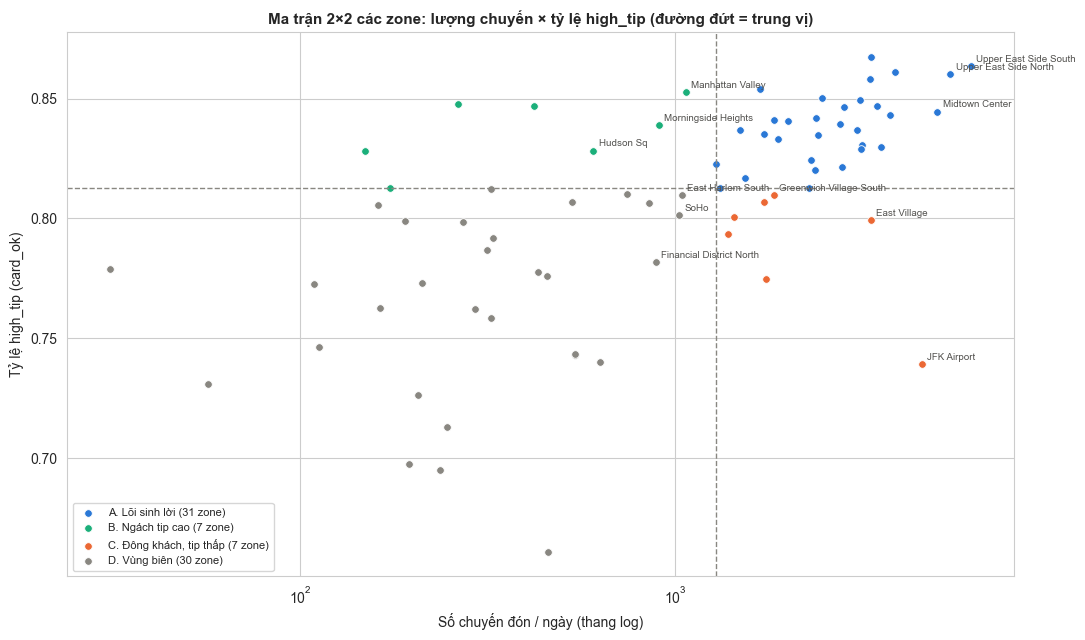

In [24]:
TIP_CUT = zone_elig["high_tip_rate"].median()
VOL_CUT = zone_elig["trips_per_day"].median()
QUAD_NAMES = {
    (True, True): "A. Lõi sinh lời",
    (True, False): "B. Ngách tip cao",
    (False, True): "C. Đông khách, tip thấp",
    (False, False): "D. Vùng biên",
}
zone_elig["quadrant"] = [QUAD_NAMES[(t >= TIP_CUT, v >= VOL_CUT)]
                         for t, v in zip(zone_elig["high_tip_rate"], zone_elig["trips_per_day"])]
print(f"Cut-offs: high_tip_rate median = {TIP_CUT:.4f} | trips/day median = {VOL_CUT:.1f}")

quad = zone_elig.groupby("quadrant").agg(
    zones=("pickup_zone", "size"),
    share_of_trips=("trips", "sum"),
    median_trips_per_day=("trips_per_day", "median"),
    median_high_tip_rate=("high_tip_rate", "median"),
    median_avg_tip_usd=("avg_tip_usd", "median"),
    median_revenue_per_trip=("revenue_per_trip", "median"),
    median_cash_share=("cash_share", "median"),
    median_avg_distance=("avg_distance", "median"),
)
quad["share_of_trips"] /= zone_tbl["trips"].sum()
quad["main_boroughs"] = zone_elig.groupby("quadrant")["pickup_borough"].agg(
    lambda s: ", ".join(f"{b} {n}" for b, n in s.value_counts().items()))
quad["examples (top volume)"] = zone_elig.sort_values("trips", ascending=False).groupby("quadrant")["pickup_zone"].agg(
    lambda s: ", ".join(s.head(4)))
print(quad.drop(columns=["main_boroughs", "examples (top volume)"]).to_string())
print()
print(quad[["main_boroughs", "examples (top volume)"]].to_string())

fig, ax = plt.subplots(figsize=(11, 6.5))
for (name, sub), c in zip(zone_elig.groupby("quadrant"), [C_BLUE, C_AQUA, C_ORANGE, C_GREY]):
    ax.scatter(sub["trips_per_day"], sub["high_tip_rate"], s=30, color=c, edgecolor="white", linewidth=0.6,
               label=f"{name} ({len(sub)} zone)")
    for _, r in sub.nlargest(3, "trips").iterrows():
        ax.annotate(r["pickup_zone"], (r["trips_per_day"], r["high_tip_rate"]), fontsize=7,
                    xytext=(4, 3), textcoords="offset points", color="#52514e")
ax.axvline(VOL_CUT, ls="--", lw=1, color=C_GREY)
ax.axhline(TIP_CUT, ls="--", lw=1, color=C_GREY)
ax.set_xscale("log")
ax.set_title("Ma trận 2×2 các zone: lượng chuyến × tỷ lệ high_tip (đường đứt = trung vị)")
ax.set_xlabel("Số chuyến đón / ngày (thang log)")
ax.set_ylabel("Tỷ lệ high_tip (card_ok)")
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

**[BẰNG CHỨNG TỪ DỮ LIỆU]** Ngưỡng: high_tip **0.8127**, **1,282.6** chuyến/ngày.

| Nhóm | Zone | % chuyến | high_tip | Tip TB | Doanh thu/chuyến | Ví dụ | Hành động |
|---|---|---|---|---|---|---|---|
| **A. Lõi sinh lời** | 31 | **69.76%** | 0.8395 | 3.74 | 20.00 | Upper East Side South/North, Midtown Center | Tài xế: thu nhập nền ổn định · Nền tảng: duy trì phủ xe |
| **B. Ngách tip cao** | 7 | 2.85% | 0.8391 | 4.03 | 23.66 | Manhattan Valley, Morningside Heights, Hudson Sq | Ứng viên "tip cao – ít xe" (5.5) |
| **C. Đông khách, tip thấp** | 7 | 12.75% | 0.7994 | 3.76 | 21.77 | JFK, East Village, Greenwich Village South, LES | Sân bay: tip USD cao · khu ăn chơi: tỷ lệ không tip cao (5.4) |
| **D. Vùng biên** | 30 | 9.49% | 0.7745 | **4.79** | **28.45** | East Harlem South, SoHo, Financial District North | Chuyến dài hơn, tip USD cao nhất → **không** né |

**Tác động:** nếu xếp hạng theo high_tip, nhóm D bị coi là "kém" dù mang lại tip USD và doanh thu/chuyến cao nhất → dễ dẫn tới quyết định sai cho tài xế.

## 5.4. Kịch bản "tip thấp" — góc nhìn khách hàng

Ô zone × khung giờ "tip thấp" = high_tip thuộc **20% thấp nhất** trong các ô đủ điều kiện; so với các ô còn lại.

In [25]:
LOW_CUT = cell_elig["high_tip_rate"].quantile(0.20)
cell_elig["is_low_tip_cell"] = cell_elig["high_tip_rate"] <= LOW_CUT
print(f"Low-tip cut-off (P20 of cell high_tip_rate) = {LOW_CUT:.4f} | "
      f"low cells = {cell_elig['is_low_tip_cell'].sum()} / {len(cell_elig)}")

cell_key = zone_src["PULocationID"].astype(str) + "|" + zone_src["slot"]
low_keys = set(cell_elig.loc[cell_elig["is_low_tip_cell"], "PULocationID"].astype(str)
               + "|" + cell_elig.loc[cell_elig["is_low_tip_cell"], "slot"])
elig_keys = set(cell_elig["PULocationID"].astype(str) + "|" + cell_elig["slot"])
grp = np.where(cell_key.isin(low_keys), "Ô tip thấp", np.where(cell_key.isin(elig_keys), "Ô còn lại", None))
cmp_src = zone_src.assign(cell_group=grp).dropna(subset=["cell_group"])

cmp_all = cmp_src.groupby("cell_group").agg(
    trips=("revenue", "size"),
    avg_distance=("trip_distance", "mean"),
    short_trip_share_lt_1mi=("trip_distance", lambda s: (s < 1).mean()),
    avg_fare=("fare_amount", "mean"),
    avg_duration=("trip_duration_min", "mean"),
    avg_speed_mph=("speed_mph", "mean"),
    airport_share=("is_airport", "mean"),
    weekend_share=("is_weekend", "mean"),
    cash_share=("is_cash", "mean"),
    unreported_payment_share=("payment_type", lambda s: (s == 0).mean()),
)
cmp_all["cross_borough_share"] = (cmp_src["pickup_borough"] != cmp_src["dropoff_borough"]).groupby(cmp_src["cell_group"]).mean()
cmp_card = cmp_src[cmp_src["card_ok"]].groupby("cell_group").agg(
    card_ok_trips=("high_tip", "size"),
    high_tip_rate=("high_tip", "mean"),
    zero_tip_share=("zero_tip", "mean"),
    small_tip_share_0_15=("tip_percentage", lambda s: ((s > 0) & (s < 0.15)).mean()),
    avg_tip_usd=("tip_amount", "mean"),
    median_tip_pct=("tip_percentage", "median"),
)
comparison = pd.concat([cmp_all, cmp_card], axis=1).T
print(comparison.to_string())

low_cells = cell_elig[cell_elig["is_low_tip_cell"]]
print("\nLow-tip cells by borough:", low_cells["pickup_borough"].value_counts().to_dict())
print("Low-tip cells by slot:", low_cells["slot"].value_counts().reindex(SLOT_ORDER).fillna(0).astype(int).to_dict())
print("\nLow-tip cells with most trips:")
print(low_cells.nlargest(12, "trips")[["pickup_borough", "pickup_zone", "slot", "trips", "high_tip_rate",
                                         "zero_tip_share", "avg_tip_usd", "fare_per_trip", "avg_distance",
                                         "cash_share"]].to_string(index=False))

Low-tip cut-off (P20 of cell high_tip_rate) = 0.7771 | low cells = 106 / 530


cell_group                    Ô còn lại   Ô tip thấp
trips                    3,245,294.0000 404,172.0000
avg_distance                     2.7798       7.6702
short_trip_share_lt_1mi          0.2315       0.0866
avg_fare                        18.8692      35.8568
avg_duration                    16.7597      27.0617
avg_speed_mph                    9.5462      15.7405
airport_share                    0.0498       0.3560
weekend_share                    0.2806       0.5835
cash_share                       0.0896       0.1278
unreported_payment_share         0.1934       0.3212
cross_borough_share              0.1009       0.3833
card_ok_trips            2,278,960.0000 209,053.0000
high_tip_rate                    0.8403       0.7451
zero_tip_share                   0.0438       0.0861
small_tip_share_0_15             0.1159       0.1688
avg_tip_usd                      4.1383       8.1944
median_tip_pct                   0.2702       0.2327

Low-tip cells by borough: {'Manhattan': 59, '

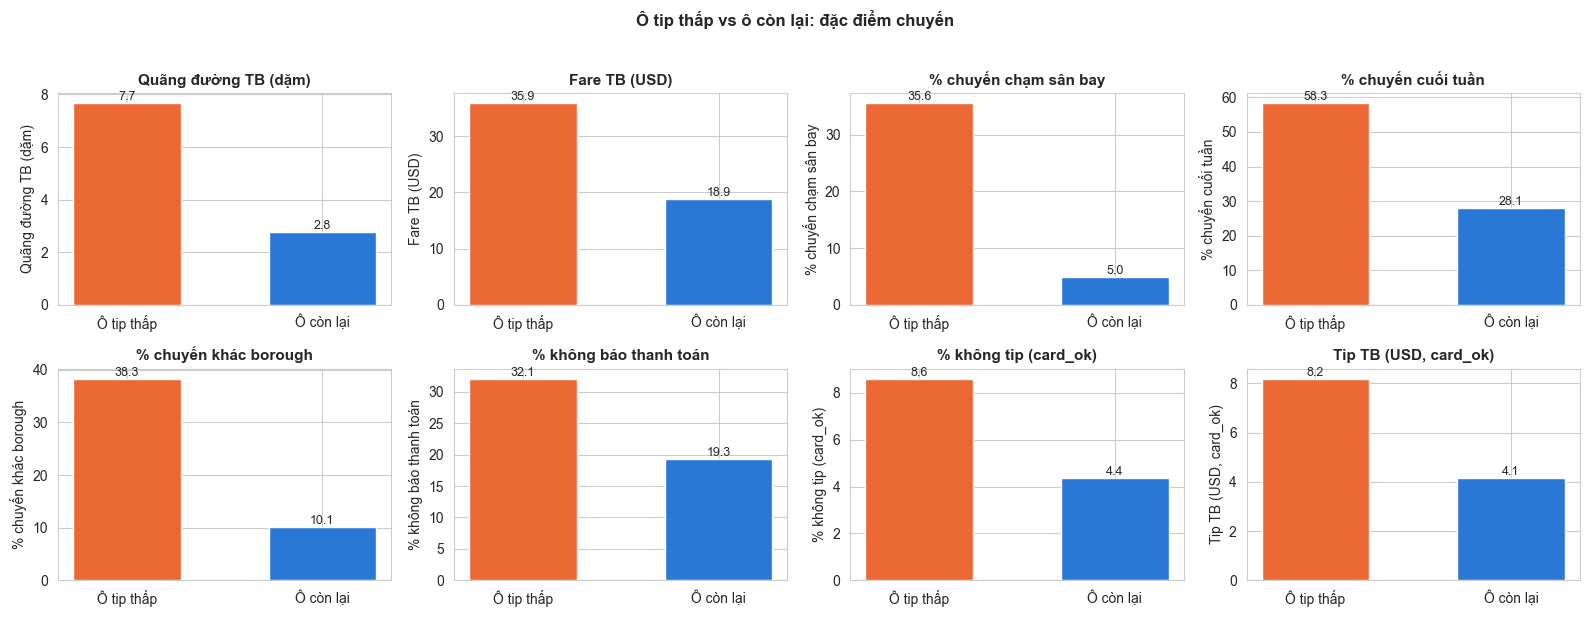

In [26]:
panels = [("avg_distance", "Quãng đường TB (dặm)", 1), ("avg_fare", "Fare TB (USD)", 1),
          ("airport_share", "% chuyến chạm sân bay", 100), ("weekend_share", "% chuyến cuối tuần", 100),
          ("cross_borough_share", "% chuyến khác borough", 100), ("unreported_payment_share", "% không báo thanh toán", 100),
          ("zero_tip_share", "% không tip (card_ok)", 100), ("avg_tip_usd", "Tip TB (USD, card_ok)", 1)]
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, (col, label, scale) in zip(axes.flat, panels):
    vals = comparison.loc[col, ["Ô tip thấp", "Ô còn lại"]].astype(float) * scale
    ax.bar(vals.index, vals.values, color=[C_ORANGE, C_BLUE], width=0.55)
    for i, v in enumerate(vals.values):
        ax.text(i, v, f"{v:.1f}", ha="center", va="bottom", fontsize=9)
    ax.set_title(label)
    ax.set_ylabel(label)
fig.suptitle("Ô tip thấp vs ô còn lại: đặc điểm chuyến", fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

**Insight:** "tip thấp" gồm 2 kiểu khác hẳn nhau: **sân bay** (tip % thấp nhưng tip USD cao) và **khu ăn chơi đêm cuối tuần** (tỷ lệ không tip gấp đôi).

**[BẰNG CHỨNG TỪ DỮ LIỆU]** 106/530 ô có high_tip ≤ **0.7771**. So với ô còn lại:
- Quãng đường **7.67** vs 2.78 dặm · fare **35.86** vs 18.87 USD · chạm sân bay **35.6%** vs 5.0% · cuối tuần **58.4%** vs 28.1%.
- Không tip **8.61%** vs 4.38% · nhưng tip TB **8.19** vs 4.14 USD.
- Không báo thanh toán **32.1%** vs 19.3% → phần lớn tip thật của các ô này **không quan sát được**.
- 31/106 ô là **đêm cuối tuần**. Ô đông nhất: JFK (mọi khung giờ, tip TB 12–14 USD) và East Village / Lower East Side / Greenwich Village South / Little Italy / Meatpacking đêm cuối tuần (chuyến 2.5–3.2 dặm, **không tip 9–12%**).

**Tác động:** tài xế — sân bay không phải "tip thấp" theo USD; khu ăn chơi đêm cuối tuần có rủi ro không tip cao nhất · khách — xem giả thuyết bên dưới.

### 5.4.1. Giả thuyết hành vi khách hàng & kiểm chứng

| # | Giả thuyết **[GIẢ THUYẾT/SUY LUẬN]** | Kiểm chứng được bằng dữ liệu? | Cách kiểm tra |
|---|---|---|---|
| H1 | Chuyến **ngắn** → khách ngại tip / làm tròn thấp | Có | high_tip theo khoảng cách, so sánh 2 nhóm ô trong cùng khoảng cách |
| H2 | **Giá đã cao** (chuyến dài, sân bay) → khách tip % thấp hơn | Có | So sánh 2 nhóm ô *trong cùng mức cước* (kiểm soát fare) |
| H3 | **Kẹt xe / giờ cao điểm** → trải nghiệm kém → tip thấp | Một phần (tốc độ là proxy kẹt xe) | high_tip theo tốc độ trung bình chuyến |
| H4 | **Khách đi làm hằng ngày** tip ít hơn khách vãng lai | Một phần (không có ID khách → chỉ so sáng ngày thường vs sáng cuối tuần ở cùng zone) | Hiệu high_tip từng cặp zone |
| H5 | **Cước cố định** (JFK flat fare, cước thoả thuận) làm tip % thấp | Có | high_tip theo `RatecodeID` |
| H6 | Khu **nhiều tiền mặt** → khách trả thẻ ở đó là nhóm khác / ít tip | Một phần (tương quan cấp zone, không nhân quả) | Spearman giữa `cash_share` và `high_tip_rate` |
| H7 | **Màn hình gợi ý tip** của thiết bị (khác nhau theo VendorID) ảnh hưởng mức tip | Có (gián tiếp) | high_tip theo VendorID trong cùng borough; phân bố tip % có "đỉnh" tại mức gợi ý? |
| H8 | **Thu nhập/văn hoá** dân cư khu vực | **Không** – không có dữ liệu nhân khẩu | Cần ghép dữ liệu Census (ngoài phạm vi) |

H1 - high_tip by distance bin:
                    mean                 size           
cell_group    Ô còn lại Ô tip thấp Ô còn lại Ô tip thấp
trip_distance                                          
(0, 1]           0.8902     0.8028    610733      21381
(1, 2]           0.8445     0.7723    809670      34123
(2, 3]           0.8035     0.7268    363206      18838
(3, 5]           0.7900     0.7159    233039      22805
(5, 10]          0.8072     0.7000    179206      19777
(10, 100]        0.8053     0.7422     83106      92129

H2 - high_tip by fare bin (controls for fare):
                  mean                 size           
cell_group  Ô còn lại Ô tip thấp Ô còn lại Ô tip thấp
fare_amount                                          
(0, 5]         0.9135     0.7951     26484        971
(5, 8]         0.9058     0.8113    408476      16425
(8, 10]        0.8728     0.7966    320403      15021
(10, 15]       0.8383     0.7566    603075      29305
(15, 20]       0.8038     0.7199    3

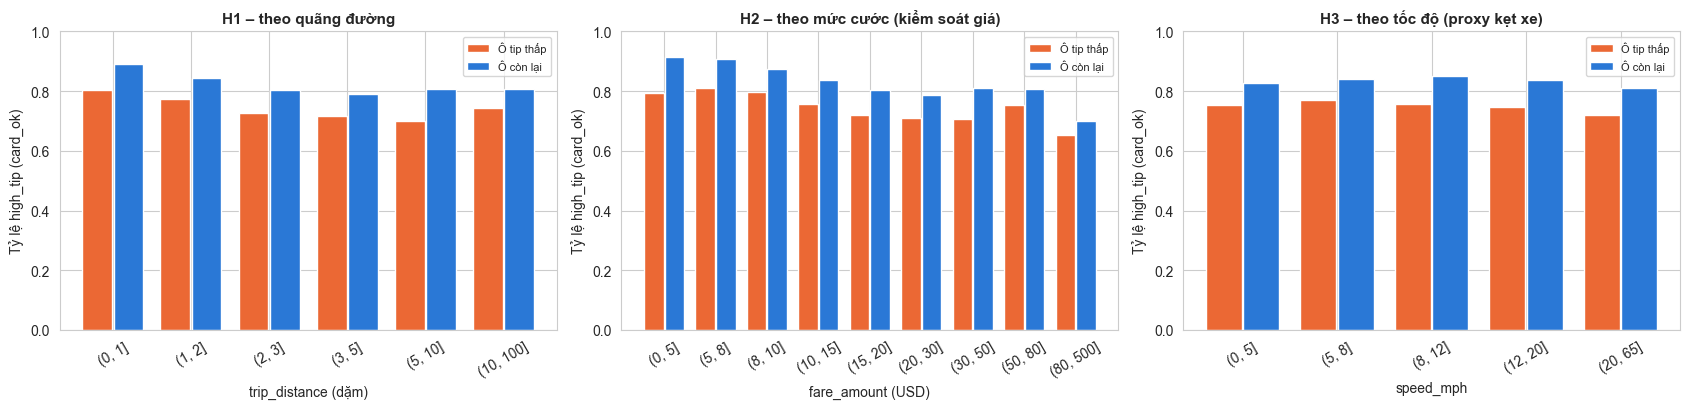

In [27]:
card_cmp = cmp_src[cmp_src["card_ok"]]
GROUP_COLORS = {"Ô tip thấp": C_ORANGE, "Ô còn lại": C_BLUE}


def rate_by_bins(df, col, bins):
    return (df.groupby([pd.cut(df[col], bins), "cell_group"], observed=True)["high_tip"]
              .agg(["mean", "size"]).unstack("cell_group"))


h1 = rate_by_bins(card_cmp, "trip_distance", [0, 1, 2, 3, 5, 10, 100])
h2 = rate_by_bins(card_cmp, "fare_amount", FARE_BINS)
h3 = rate_by_bins(card_cmp, "speed_mph", [0, 5, 8, 12, 20, 65])
print("H1 - high_tip by distance bin:\n", h1.to_string())
print("\nH2 - high_tip by fare bin (controls for fare):\n", h2.to_string())
print("\nH3 - high_tip by speed bin:\n", h3.to_string())

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, tbl, title, xl in [(axes[0], h1, "H1 – theo quãng đường", "trip_distance (dặm)"),
                           (axes[1], h2, "H2 – theo mức cước (kiểm soát giá)", "fare_amount (USD)"),
                           (axes[2], h3, "H3 – theo tốc độ (proxy kẹt xe)", "speed_mph")]:
    x = np.arange(len(tbl))
    for i, (g, c) in enumerate(GROUP_COLORS.items()):
        ax.bar(x + (i - 0.5) * 0.4, tbl[("mean", g)], width=0.38, color=c, label=g)
    ax.set_xticks(x, [str(b) for b in tbl.index], rotation=30)
    ax.set_title(title)
    ax.set_xlabel(xl)
    ax.set_ylabel("Tỷ lệ high_tip (card_ok)")
    ax.set_ylim(0, 1)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [28]:
# H4 - weekday vs weekend early morning in the same zone (paired)
pv_morning = cell_elig[cell_elig["slot"].str.endswith("early_morning")].pivot(
    index="pickup_zone", columns="slot", values="high_tip_rate").dropna()
h4_diff = pv_morning["weekday|early_morning"] - pv_morning["weekend|early_morning"]
print(f"H4 - zones with both mornings: {len(pv_morning)} | mean(weekday - weekend) = {h4_diff.mean():+.4f} | "
      f"median = {h4_diff.median():+.4f} | share of zones weekday lower = {(h4_diff < 0).mean():.2%}")

# H5 - by rate code (card_ok trips, all eligible cells)
RATE_NAMES = {1: "1-Standard", 2: "2-JFK flat", 3: "3-Newark", 4: "4-Nassau/Westchester", 5: "5-Negotiated"}
h5 = (card_ok[card_ok["RatecodeID"].isin(RATE_NAMES)]
      .groupby("RatecodeID").agg(trips=("high_tip", "size"), high_tip_rate=("high_tip", "mean"),
                                 avg_tip_usd=("tip_amount", "mean"), avg_fare=("fare_amount", "mean"),
                                 zero_tip_share=("zero_tip", "mean")))
h5.index = h5.index.map(RATE_NAMES)
print("\nH5 - by RatecodeID:\n", h5.to_string())
print("Share of card_ok trips in low-tip cells with RatecodeID 2-5:",
      f"{card_cmp.groupby('cell_group')['RatecodeID'].apply(lambda s: s.isin([2, 3, 4, 5]).mean()).round(4).to_dict()}")

# H6 - zone-level association between cash share and high_tip rate
rho, pval = spearmanr(zone_elig["cash_share"], zone_elig["high_tip_rate"])
print(f"\nH6 - Spearman(cash_share, high_tip_rate) over {len(zone_elig)} zones: rho = {rho:.4f}, p = {pval:.2e}")

# H7 - vendor (tip-screen device) within borough
h7 = (card_ok[card_ok["pickup_borough"].isin(["Manhattan", "Queens", "Brooklyn", "Bronx"])]
      .groupby(["pickup_borough", "VendorID"]).agg(trips=("high_tip", "size"), high_tip_rate=("high_tip", "mean"),
                                                   zero_tip_share=("zero_tip", "mean"))
      .query("trips >= 300"))
print("\nH7 - by borough x VendorID:\n", h7.to_string())

H4 - zones with both mornings: 53 | mean(weekday - weekend) = -0.0121 | median = -0.0119 | share of zones weekday lower = 62.26%



H5 - by RatecodeID:
                         trips  high_tip_rate  avg_tip_usd  avg_fare  zero_tip_share
RatecodeID                                                                         
1-Standard            2396765         0.8358       4.0510   16.9491          0.0467
2-JFK flat              77578         0.7644      14.3787   70.0014          0.0487
3-Newark                 8644         0.7444      16.2708   80.9390          0.0792
4-Nassau/Westchester     6211         0.6319      18.2215  114.9957          0.1290
5-Negotiated            14488         0.6711      12.8461   77.2586          0.1429


Share of card_ok trips in low-tip cells with RatecodeID 2-5: {'Ô còn lại': 0.015, 'Ô tip thấp': 0.3266}

H6 - Spearman(cash_share, high_tip_rate) over 75 zones: rho = 0.4830, p = 1.14e-05



H7 - by borough x VendorID:
                            trips  high_tip_rate  zero_tip_share
pickup_borough VendorID                                        
Bronx          2             464         0.6573          0.1767
Brooklyn       1            1291         0.8288          0.0767
               2            8393         0.7762          0.0953
Manhattan      1          421352         0.8639          0.0379
               2         1859110         0.8292          0.0485
Queens         1           29111         0.8292          0.0498
               2          179984         0.7876          0.0579


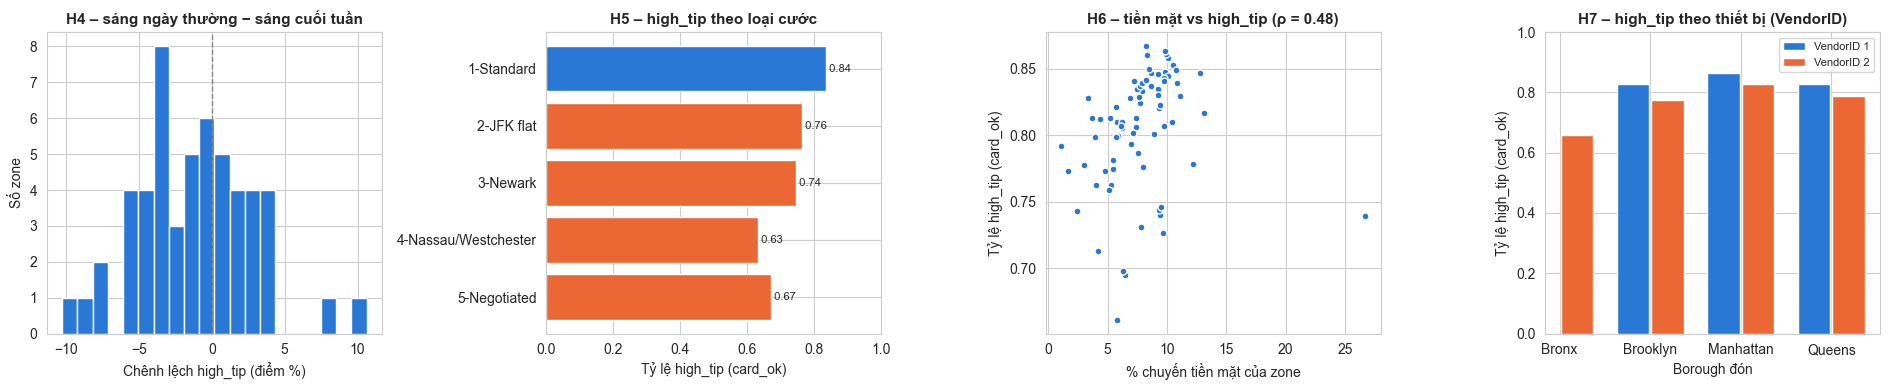

In [29]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
ax = axes[0]
ax.hist(h4_diff * 100, bins=20, color=C_BLUE)
ax.axvline(0, ls="--", lw=1, color=C_GREY)
ax.set_title("H4 – sáng ngày thường − sáng cuối tuần")
ax.set_xlabel("Chênh lệch high_tip (điểm %)")
ax.set_ylabel("Số zone")

ax = axes[1]
ax.barh(h5.index, h5["high_tip_rate"], color=[C_BLUE] + [C_ORANGE] * (len(h5) - 1))
for yi, v in enumerate(h5["high_tip_rate"]):
    ax.text(v, yi, f" {v:.2f}", va="center", fontsize=8)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_title("H5 – high_tip theo loại cước")
ax.set_xlabel("Tỷ lệ high_tip (card_ok)")

ax = axes[2]
ax.scatter(zone_elig["cash_share"] * 100, zone_elig["high_tip_rate"], s=25, color=C_BLUE, edgecolor="white")
ax.set_title(f"H6 – tiền mặt vs high_tip (ρ = {rho:.2f})")
ax.set_xlabel("% chuyến tiền mặt của zone")
ax.set_ylabel("Tỷ lệ high_tip (card_ok)")

ax = axes[3]
h7p = h7["high_tip_rate"].unstack("VendorID")
xx = np.arange(len(h7p))
for i, (v, c) in enumerate(zip(h7p.columns, [C_BLUE, C_ORANGE])):
    ax.bar(xx + (i - 0.5) * 0.38, h7p[v], width=0.36, color=c, label=f"VendorID {v}")
ax.set_xticks(xx, h7p.index)
ax.set_ylim(0, 1)
ax.set_title("H7 – high_tip theo thiết bị (VendorID)")
ax.set_xlabel("Borough đón")
ax.set_ylabel("Tỷ lệ high_tip (card_ok)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

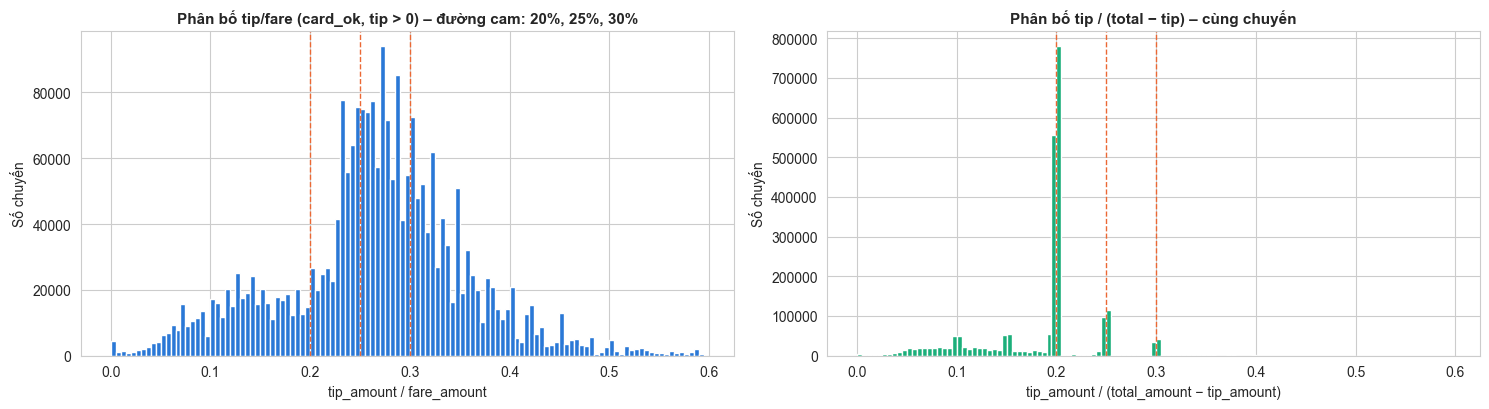

Share of tipped card_ok trips whose tip is exactly 20/25/30% of pre-tip total (±0.5pt): 68.54%
Top 6 most frequent rounded tip/(total-tip) values:
0.2000   0.5641
0.2500   0.0893
0.1500   0.0440
0.1000   0.0413
0.3000   0.0320
0.1900   0.0267


In [30]:
tipped = card_ok[(card_ok["tip_amount"] > 0) & (card_ok["tip_percentage"] < 0.6)]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
ax = axes[0]
ax.hist(tipped["tip_percentage"], bins=np.arange(0, 0.6, 0.005), color=C_BLUE)
for v in (0.20, 0.25, 0.30):
    ax.axvline(v, ls="--", lw=1, color=C_ORANGE)
ax.set_title("Phân bố tip/fare (card_ok, tip > 0) – đường cam: 20%, 25%, 30%")
ax.set_xlabel("tip_amount / fare_amount")
ax.set_ylabel("Số chuyến")

# Tip screens usually compute % on the pre-tip total, not on fare only -> check that base as well
tip_base = tipped["total_amount"] - tipped["tip_amount"]
ax = axes[1]
ax.hist(tipped["tip_amount"] / tip_base, bins=np.arange(0, 0.6, 0.005), color=C_AQUA)
for v in (0.20, 0.25, 0.30):
    ax.axvline(v, ls="--", lw=1, color=C_ORANGE)
ax.set_title("Phân bố tip / (total − tip) – cùng chuyến")
ax.set_xlabel("tip_amount / (total_amount − tip_amount)")
ax.set_ylabel("Số chuyến")
plt.tight_layout()
plt.show()

ratio_total = (tipped["tip_amount"] / tip_base).round(2)
print("Share of tipped card_ok trips whose tip is exactly 20/25/30% of pre-tip total (±0.5pt):",
      f"{ratio_total.isin([0.20, 0.25, 0.30]).mean():.2%}")
print("Top 6 most frequent rounded tip/(total-tip) values:")
print(ratio_total.value_counts(normalize=True).head(6).round(4).to_string())

**Kết quả kiểm chứng (số liệu ở các cell và biểu đồ trên)**

| # | Giả thuyết [GIẢ THUYẾT/SUY LUẬN] | Bằng chứng [BẰNG CHỨNG TỪ DỮ LIỆU] | Kết luận |
|---|---|---|---|
| H1 | Chuyến ngắn → tip thấp | Chuyến ≤ 1 dặm có high_tip **cao nhất** (0.8902); ô tip thấp vẫn thấp hơn 6–11 điểm ở **mọi** khoảng cách | **Bác bỏ** |
| H2 | Giá đã cao → tip % thấp | Cùng mức cước, ô tip thấp vẫn thấp hơn (10–15 USD: 0.7566 vs 0.8383) | **Một phần**: giá cao giảm tip %, nhưng không giải thích chênh lệch giữa khu |
| H3 | Kẹt xe/cao điểm → tip thấp | 0–5 mph: 0.8286 ≈ 8–12 mph: 0.8494; giờ cao điểm ngày thường có high_tip **cao nhất** (0.8437) | **Không ủng hộ** |
| H4 | Khách đi làm tip ít hơn | Sáng ngày thường thấp hơn sáng cuối tuần **1.21 điểm %**, ở **62%** zone | **Ủng hộ yếu**, hiệu ứng nhỏ, không có ID khách |
| H5 | Cước cố định/thoả thuận → tip % thấp | Standard **0.836** · JFK flat 0.764 · Negotiated 0.671; ô tip thấp có **32.7%** chuyến cước 2–5 (ô thường: 1.5%) | **Ủng hộ** – động lực chính ở sân bay |
| H6 | Khu nhiều tiền mặt → khách thẻ tip ít | Spearman **+0.48** (p = 1.1e-5) – **cùng chiều** | **Bác bỏ** |
| H7 | Nút gợi ý tip chi phối mức tip | **56.4%** chuyến tip đúng **20%** tổng trước tip; **68.5%** đúng 20/25/30%; VendorID 1 > VendorID 2 ở mọi borough (Manhattan 0.864 vs 0.829) | **Ủng hộ mạnh** |
| H8 | Thu nhập/văn hoá dân cư | Không có dữ liệu | **Không kiểm chứng được** |

**Insight cho khách hàng:** hành vi tip thẻ = **bấm nút mặc định**. "Tip thấp" thực chất là khách **chủ động** chọn không tip / 10% / tự nhập — xảy ra nhiều ở khu ăn chơi đêm cuối tuần và với cước cố định.

**Tác động:** nền tảng — thiết kế nút gợi ý (mức mặc định, cách tính % trên tổng tiền) là đòn bẩy tip lớn nhất, lớn hơn mọi yếu tố khu vực/giờ; khách — cần minh bạch rằng % tính trên tổng tiền gồm phụ phí.

## 5.5. Kịch bản "tip cao nhưng ít xe" — góc nhìn tài xế

| Proxy (zone × khung giờ) | Công thức | Giới hạn |
|---|---|---|
| Cầu | `pickups_per_hour` = chuyến đón ÷ số giờ của khung trong tháng | Không thấy cầu bị bỏ lỡ |
| Cung xe rỗng tại chỗ | `flow_ratio` = chuyến **kết thúc** ÷ chuyến **bắt đầu** tại zone (< 1: phải có xe rỗng từ nơi khác tới) | Không thấy xe rỗng đi ngang, xe nghỉ, hàng chờ sân bay |
| Thu nhập/giờ có khách | Σ(fare + tip thẻ) ÷ Σ thời lượng × 60 | Không tính thời gian chờ/chạy rỗng |

In [31]:
hours = pd.Series(pd.date_range("2026-05-01", "2026-06-01", freq="h", inclusive="left"))
SLOT_HOURS = slot_label(hours).value_counts()
print("Hours per slot in May 2026:", SLOT_HOURS.reindex(SLOT_ORDER).to_dict())

drop_src = trips[trips["do_in_month"] & ~trips["DOLocationID"].isin(UNKNOWN_ZONE_IDS)]
dropoffs = drop_src.groupby(["DOLocationID", "dropoff_slot"]).size().rename("dropoffs")
dropoffs.index.names = ["PULocationID", "slot"]

flow = cell_tbl.set_index(["PULocationID", "slot"]).join(dropoffs).reset_index()
flow["dropoffs"] = flow["dropoffs"].fillna(0)
flow["slot_hours"] = flow["slot"].map(SLOT_HOURS)
flow["pickups_per_hour"] = flow["trips"] / flow["slot_hours"]
flow["dropoffs_per_hour"] = flow["dropoffs"] / flow["slot_hours"]
flow["flow_ratio"] = flow["dropoffs"] / flow["trips"]
flow["net_outflow_per_hour"] = flow["pickups_per_hour"] - flow["dropoffs_per_hour"]
flow["tip_share_of_revenue"] = (flow["avg_tip_usd"] * flow["card_ok_trips"]) / (flow["revenue_per_trip"] * flow["trips"])

MIN_PICKUPS_PER_HOUR = 1.0
flow_elig = flow[(flow["card_ok_trips"] >= MIN_CARD_CELL) & (flow["pickups_per_hour"] >= MIN_PICKUPS_PER_HOUR)].copy()
print(f"Eligible cells (>= {MIN_CARD_CELL} card_ok trips and >= {MIN_PICKUPS_PER_HOUR} pickup/hour): {len(flow_elig)}")
print(flow_elig[["pickups_per_hour", "flow_ratio", "high_tip_rate", "avg_tip_usd",
                 "revenue_per_trip", "revenue_per_occ_hour"]].describe(percentiles=[.25, .5, .75]).T.to_string())

# Zone-level occupied income (all slots)
zone_income = zone_elig.set_index(["pickup_borough", "pickup_zone"])[["trips_per_day", "revenue_per_trip",
                                                                      "avg_duration", "revenue_per_occ_hour",
                                                                      "high_tip_rate", "avg_tip_usd"]]
print("\nTop 8 zones by revenue per occupied hour:\n", zone_income.nlargest(8, "revenue_per_occ_hour").to_string())
print("\nBottom 8 zones by revenue per occupied hour:\n", zone_income.nsmallest(8, "revenue_per_occ_hour").to_string())

Hours per slot in May 2026: {'weekday|early_morning': 84, 'weekday|midday': 126, 'weekday|peak_hour': 84, 'weekday|late_night': 210, 'weekend|early_morning': 40, 'weekend|midday': 60, 'weekend|peak_hour': 40, 'weekend|late_night': 100}


Eligible cells (>= 100 card_ok trips and >= 1.0 pickup/hour): 530
                        count    mean     std     min     25%     50%      75%      max
pickups_per_hour     530.0000 76.9008 77.7396  1.9524 18.9327 54.8234 109.8275 474.0833
flow_ratio           530.0000  1.1818  0.6203  0.0798  0.8161  1.0473   1.4387   4.0341
high_tip_rate        530.0000  0.8099  0.0507  0.5446  0.7879  0.8234   0.8460   0.8947
avg_tip_usd          530.0000  4.5596  2.1894  2.7893  3.4831  3.8476   4.5074  15.4581
revenue_per_trip     530.0000 24.9017  9.9282 15.8385 19.4916 21.6687  26.3795  78.8264
revenue_per_occ_hour 530.0000 80.5211 11.3540 47.1792 73.5235 79.9513  85.4840 147.6800

Top 8 zones by revenue per occupied hour:
                                                trips_per_day  revenue_per_trip  avg_duration  revenue_per_occ_hour  high_tip_rate  avg_tip_usd
pickup_borough pickup_zone                                                                                                         

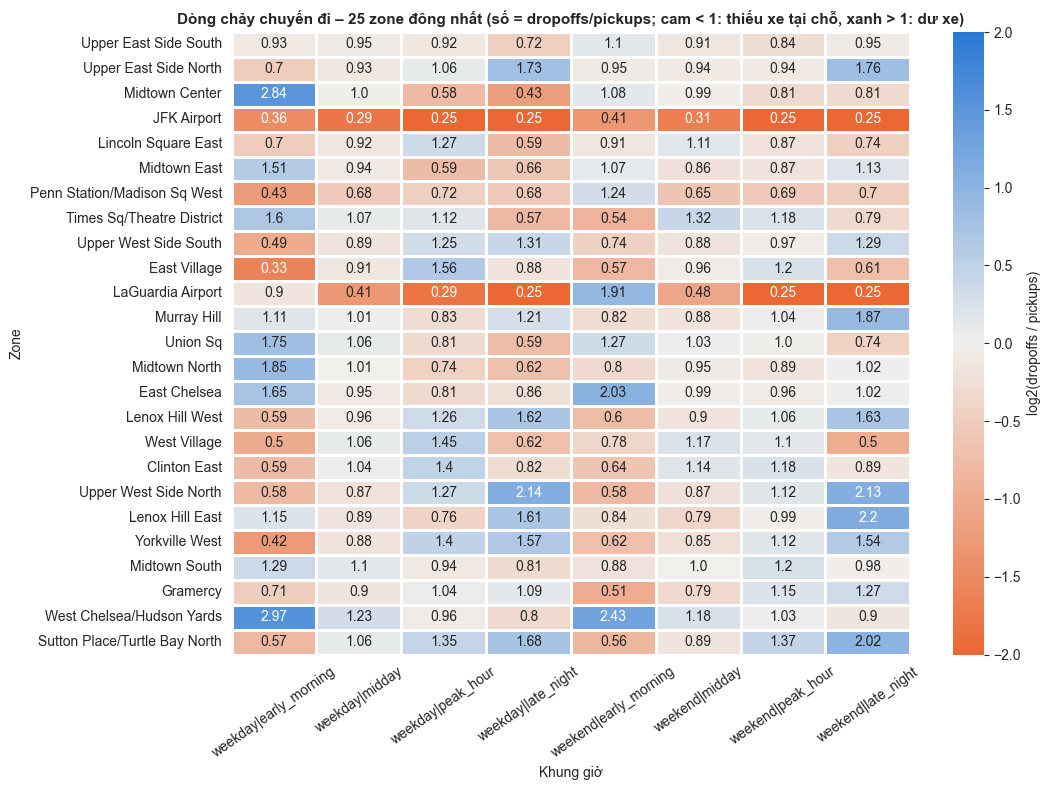

In [32]:
top25 = zone_elig.nlargest(25, "trips")["PULocationID"]
pv_flow = (flow[flow["PULocationID"].isin(top25)]
           .assign(log2_ratio=lambda d: np.log2(d["flow_ratio"].clip(0.25, 4)))
           .pivot(index="pickup_zone", columns="slot", values="log2_ratio")[SLOT_ORDER])
pv_flow = pv_flow.loc[zone_elig.set_index("pickup_zone").loc[pv_flow.index, "trips"].sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(pv_flow, cmap=DIV_CMAP, center=0, vmin=-2, vmax=2, annot=np.exp2(pv_flow).round(2), fmt="",
            cbar_kws={"label": "log2(dropoffs / pickups)"}, ax=ax, linewidths=1, linecolor="white")
ax.set_title("Dòng chảy chuyến đi – 25 zone đông nhất (số = dropoffs/pickups; cam < 1: thiếu xe tại chỗ, xanh > 1: dư xe)")
ax.set_xlabel("Khung giờ")
ax.set_ylabel("Zone")
ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

**Insight:** dòng chảy chuyến đi lộ rõ mẫu hình đi làm; proxy cung **không dùng được ở sân bay**.

**[BẰNG CHỨNG TỪ DỮ LIỆU]**
- Văn phòng (Midtown Center, Hudson Yards): sáng ngày thường dropoffs/pickups **2.84 / 2.97** (dư xe), tối **0.43** (thiếu xe).
- Dân cư (Upper West/East Side): sáng < 1, đêm > 1 (UWS North **2.14**).
- Thu nhập/giờ có khách: JFK **96.06**, LaGuardia 93.16 USD; thấp nhất Central Harlem North **64.18** USD (chênh **~50%**).

**[GIẢ THUYẾT/SUY LUẬN]** taxi tới sân bay rỗng để xếp hàng ở bãi chờ (không có trong dữ liệu) → `flow_ratio` thấp ở JFK/LGA không có nghĩa là thiếu xe.

**Tác động:** nền tảng — điều phối xe rỗng theo hướng ngược dòng chảy (sáng: văn phòng → dân cư; tối: ngược lại).

### 5.5.1. Tìm các ô "tip cao nhưng cung thấp"

- **Ô mục tiêu (tip cao – cung thấp):** `high_tip_rate` ≥ P75 **và** `flow_ratio` ≤ P25 (trong các ô đủ điều kiện).
- **Ô xuất phát (dư xe):** `flow_ratio` ≥ P75 trong **cùng khung giờ** — nơi xe rỗng tích tụ.

Cut-offs: high_tip P75 = 0.8460 | flow_ratio P25 = 0.8161 | P75 = 1.4387
Target cells: 41 | origin (oversupplied) cells: 133

Target cells (high tip, thin local supply):
pickup_borough                   pickup_zone                  slot  pickups_per_hour  dropoffs_per_hour  flow_ratio  high_tip_rate  avg_tip_usd  revenue_per_trip  avg_duration  revenue_per_occ_hour  airport_share  airport_fee_share  airport_related
     Manhattan                 Midtown North     weekday|peak_hour          252.5119           186.7857      0.7397         0.8476       4.1403           20.2497       17.0659               71.1937         0.0164             0.0000            False
        Queens             LaGuardia Airport        weekday|midday          228.2937            93.6667      0.4103         0.8690      11.9820           61.0285       44.9635               81.4374         1.0000             0.9924             True
        Queens             LaGuardia Airport     weekday|peak_hour          215.738

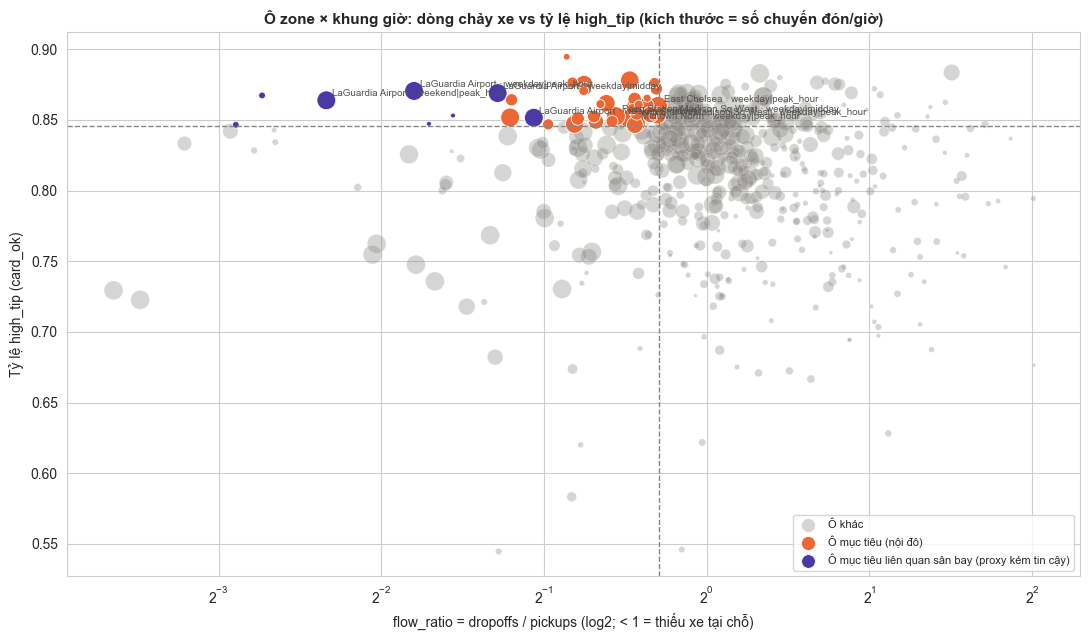

In [33]:
TIP_P75 = flow_elig["high_tip_rate"].quantile(0.75)
FLOW_P25 = flow_elig["flow_ratio"].quantile(0.25)
FLOW_P75 = flow_elig["flow_ratio"].quantile(0.75)
flow_elig["is_target"] = (flow_elig["high_tip_rate"] >= TIP_P75) & (flow_elig["flow_ratio"] <= FLOW_P25)
flow_elig["is_origin"] = flow_elig["flow_ratio"] >= FLOW_P75
print(f"Cut-offs: high_tip P75 = {TIP_P75:.4f} | flow_ratio P25 = {FLOW_P25:.4f} | P75 = {FLOW_P75:.4f}")
print(f"Target cells: {flow_elig['is_target'].sum()} | origin (oversupplied) cells: {flow_elig['is_origin'].sum()}")

targets = flow_elig[flow_elig["is_target"]].sort_values("pickups_per_hour", ascending=False).copy()
# Cells where most trips touch an airport: empty cabs queue in airport holding lots,
# which the dropoff/pickup flow cannot see -> the supply proxy is unreliable there
# Airport_fee is only charged on pickups at LGA/JFK -> also catches airport pickups geocoded to a neighbouring zone
targets["airport_related"] = (targets["airport_share"] >= 0.5) | (targets["airport_fee_share"] >= 0.5)
tcols = ["pickup_borough", "pickup_zone", "slot", "pickups_per_hour", "dropoffs_per_hour", "flow_ratio",
         "high_tip_rate", "avg_tip_usd", "revenue_per_trip", "avg_duration", "revenue_per_occ_hour",
         "airport_share", "airport_fee_share", "airport_related"]
print("\nTarget cells (high tip, thin local supply):")
print(targets[tcols].to_string(index=False))
print("\nTarget cells by slot:", targets["slot"].value_counts().reindex(SLOT_ORDER).fillna(0).astype(int).to_dict())
print("Target cells by borough:", targets["pickup_borough"].value_counts().to_dict())
print("Airport-related target cells:", int(targets["airport_related"].sum()), "/", len(targets))

fig, ax = plt.subplots(figsize=(11, 6.5))
rest = flow_elig[~flow_elig["is_target"]]
ax.scatter(rest["flow_ratio"], rest["high_tip_rate"], s=rest["pickups_per_hour"].clip(upper=150) * 1.2 + 4,
           color=C_GREY, alpha=0.35, edgecolor="white", linewidth=0.4, label="Ô khác")
for is_ap, c, lab in [(False, C_ORANGE, "Ô mục tiêu (nội đô)"), (True, C_VIOLET, "Ô mục tiêu liên quan sân bay (proxy kém tin cậy)")]:
    sub = targets[targets["airport_related"] == is_ap]
    ax.scatter(sub["flow_ratio"], sub["high_tip_rate"], s=sub["pickups_per_hour"].clip(upper=150) * 1.2 + 4,
               color=c, edgecolor="white", linewidth=0.6, label=lab)
for _, r in targets.head(8).iterrows():
    ax.annotate(f"{r['pickup_zone']} · {r['slot']}", (r["flow_ratio"], r["high_tip_rate"]), fontsize=7,
                xytext=(4, 3), textcoords="offset points", color="#52514e")
ax.axvline(FLOW_P25, ls="--", lw=1, color=C_GREY)
ax.axhline(TIP_P75, ls="--", lw=1, color=C_GREY)
ax.set_xscale("log", base=2)
ax.set_title("Ô zone × khung giờ: dòng chảy xe vs tỷ lệ high_tip (kích thước = số chuyến đón/giờ)")
ax.set_xlabel("flow_ratio = dropoffs / pickups (log2; < 1 = thiếu xe tại chỗ)")
ax.set_ylabel("Tỷ lệ high_tip (card_ok)")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

**[BẰNG CHỨNG TỪ DỮ LIỆU]** 41 ô "tip cao (≥ 0.8460) – cung thấp (flow ≤ 0.8161)"; 133 ô dư xe (flow ≥ 1.4387).

| Kiểu | Số ô | Ví dụ | Đặc điểm |
|---|---|---|---|
| Sân bay (LGA + East Elmhurst) | 8 | LaGuardia trưa/cao điểm | 47–61 USD/chuyến, tip TB 9.9–12.0 USD; East Elmhurst có **81–86%** chuyến thu `Airport_fee` → thực chất là đón ở LGA; **proxy không tin cậy** |
| Văn phòng/giao thông Manhattan chiều–tối ngày thường | – | Midtown Center đêm (flow **0.43**, 164 chuyến/giờ, 91.89 USD/giờ có khách), Times Sq, Penn Station, Midtown North | Cầu lớn, xe rỗng đổ vào ít |
| Dân cư UES/UWS sáng sớm cuối tuần | **12** | Yorkville East (flow **0.44**), UWS, Lenox Hill, Sutton Place | high_tip 0.85–0.89, phần lớn **92–96 USD/giờ có khách** |

### 5.5.2. Ước tính tác động nếu tài xế dịch chuyển

**[GIẢ ĐỊNH KỊCH BẢN]** $\text{income}_c = 60 \cdot R_c / (D_c + W_c)$ với $R_c, D_c$ = doanh thu & thời lượng TB/chuyến (**đo từ dữ liệu**), thời gian chờ $W_c = W_0 \cdot \text{flow\_ratio}_c$ (2–45 phút), $W_0 \in \{5, 10, 15\}$; chạy rỗng một lần $T \in \{10, 20, 30\}$ phút/ca 4h; ô xuất phát = TB các ô dư xe cùng khung giờ. Hệ thống: các ô mục tiêu hấp thụ thêm α ∈ {5, 10, 20}% chuyến (**cận trên**, vì cầu bị bỏ lỡ không quan sát được).

In [34]:
W0_OPTIONS = [5, 10, 15]          # assumed wait (min) when flow_ratio == 1
DEADHEAD_OPTIONS = [10, 20, 30]   # one-off empty drive (min) to reach the target zone
SHIFT_HOURS = 4
BASE_W0, BASE_DEADHEAD = 10, 20


def hourly_income(rev_per_trip, duration, flow_ratio, w0):
    wait = np.clip(w0 * flow_ratio, 2, 45)
    return 60 * rev_per_trip / (duration + wait)


def weighted(df, col, w="trips"):
    return np.average(df[col], weights=df[w])


origin_by_slot = (flow_elig[flow_elig["is_origin"]].groupby("slot")
                  .apply(lambda d: pd.Series({c: weighted(d, c) for c in ["revenue_per_trip", "avg_duration", "flow_ratio"]}))
                  .add_prefix("origin_"))
print("Oversupplied (origin) reference by slot:\n", origin_by_slot.reindex(SLOT_ORDER).to_string())

scen = targets.merge(origin_by_slot, left_on="slot", right_index=True, how="left")
scen["income_origin"] = hourly_income(scen["origin_revenue_per_trip"], scen["origin_avg_duration"],
                                      scen["origin_flow_ratio"], BASE_W0)
scen["income_target"] = hourly_income(scen["revenue_per_trip"], scen["avg_duration"], scen["flow_ratio"], BASE_W0)
scen["gain_per_hour"] = scen["income_target"] * (1 - BASE_DEADHEAD / (60 * SHIFT_HOURS)) - scen["income_origin"]
scen["gain_per_shift"] = scen["gain_per_hour"] * SHIFT_HOURS
print(f"\nPer-driver scenario (W0={BASE_W0} min, deadhead={BASE_DEADHEAD} min, shift={SHIFT_HOURS}h):")
print(scen[["pickup_zone", "slot", "flow_ratio", "origin_flow_ratio", "revenue_per_trip", "origin_revenue_per_trip",
            "income_target", "income_origin", "gain_per_hour", "gain_per_shift"]].to_string(index=False))

print("\nMedian gain/hour - urban targets: "
      f"{scen.loc[~scen['airport_related'], 'gain_per_hour'].median():.2f} | airport-related: "
      f"{scen.loc[scen['airport_related'], 'gain_per_hour'].median():.2f}")

# Sensitivity on URBAN targets only (the flow proxy is unreliable for airport queues)
urban = scen[~scen["airport_related"]]
sens = pd.DataFrame(index=pd.Index(W0_OPTIONS, name="W0 (min)"),
                    columns=pd.Index(DEADHEAD_OPTIONS, name="deadhead (min)"), dtype=float)
for w0 in W0_OPTIONS:
    for dh in DEADHEAD_OPTIONS:
        inc_t = hourly_income(urban["revenue_per_trip"], urban["avg_duration"], urban["flow_ratio"], w0)
        inc_o = hourly_income(urban["origin_revenue_per_trip"], urban["origin_avg_duration"], urban["origin_flow_ratio"], w0)
        sens.loc[w0, dh] = np.median(inc_t * (1 - dh / (60 * SHIFT_HOURS)) - inc_o)
print(f"\nSensitivity - median gain (USD/hour) across {len(urban)} urban target cells:\n", sens.round(2).to_string())

# Same scenario WITHOUT the wait-time assumption (W = 0): pure occupied-time productivity difference
occ_gap = (60 * urban["revenue_per_trip"] / urban["avg_duration"]
           - 60 * urban["origin_revenue_per_trip"] / urban["origin_avg_duration"])
print(f"\nUrban targets - occupied-hour revenue gap without any wait assumption: median {occ_gap.median():.2f} USD/h, "
      f"positive in {(occ_gap > 0).mean():.0%} of cells")

Oversupplied (origin) reference by slot:
                        origin_revenue_per_trip  origin_avg_duration  origin_flow_ratio
slot                                                                                  
weekday|early_morning                  22.6938              16.8211             1.8762
weekday|midday                         30.4962              27.2696             1.5614
weekday|peak_hour                      21.6852              18.3888             1.7712
weekday|late_night                     21.3027              14.7990             1.9115
weekend|early_morning                  27.8437              16.2629             1.9338
weekend|midday                         24.7272              20.2698             1.5804
weekend|peak_hour                      22.6574              18.6314             1.5790
weekend|late_night                     19.7846              14.2976             1.9979

Per-driver scenario (W0=10 min, deadhead=20 min, shift=4h):
                  pickup_zo

   target group alpha (extra demand absorbed)  extra_trips_per_month  extra_revenue_usd_per_month  extra_card_tip_usd_per_month  driver_hours_needed  share_of_all_month_revenue
          urban                            5%            16,810.5500                 348,081.9700                   48,565.7370           7,126.6716                      0.0037
          urban                           10%            33,621.1000                 696,163.9400                   97,131.4740          14,253.3432                      0.0073
          urban                           20%            67,242.2000               1,392,327.8800                  194,262.9480          28,506.6863                      0.0147
airport-related                            5%             3,530.6000                 205,611.7720                   35,903.5450           2,965.4383                      0.0022
airport-related                           10%             7,061.2000                 411,223.5440                  

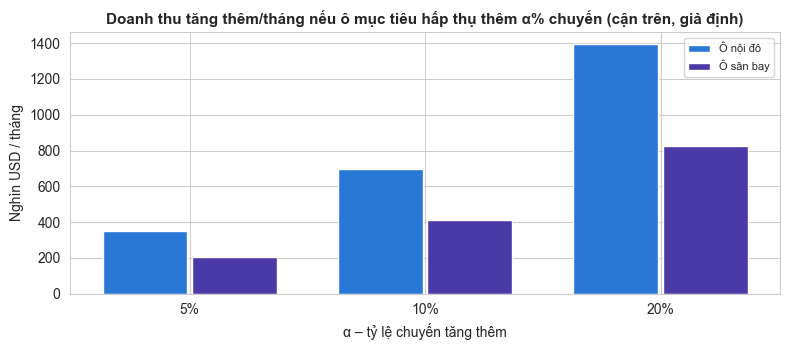

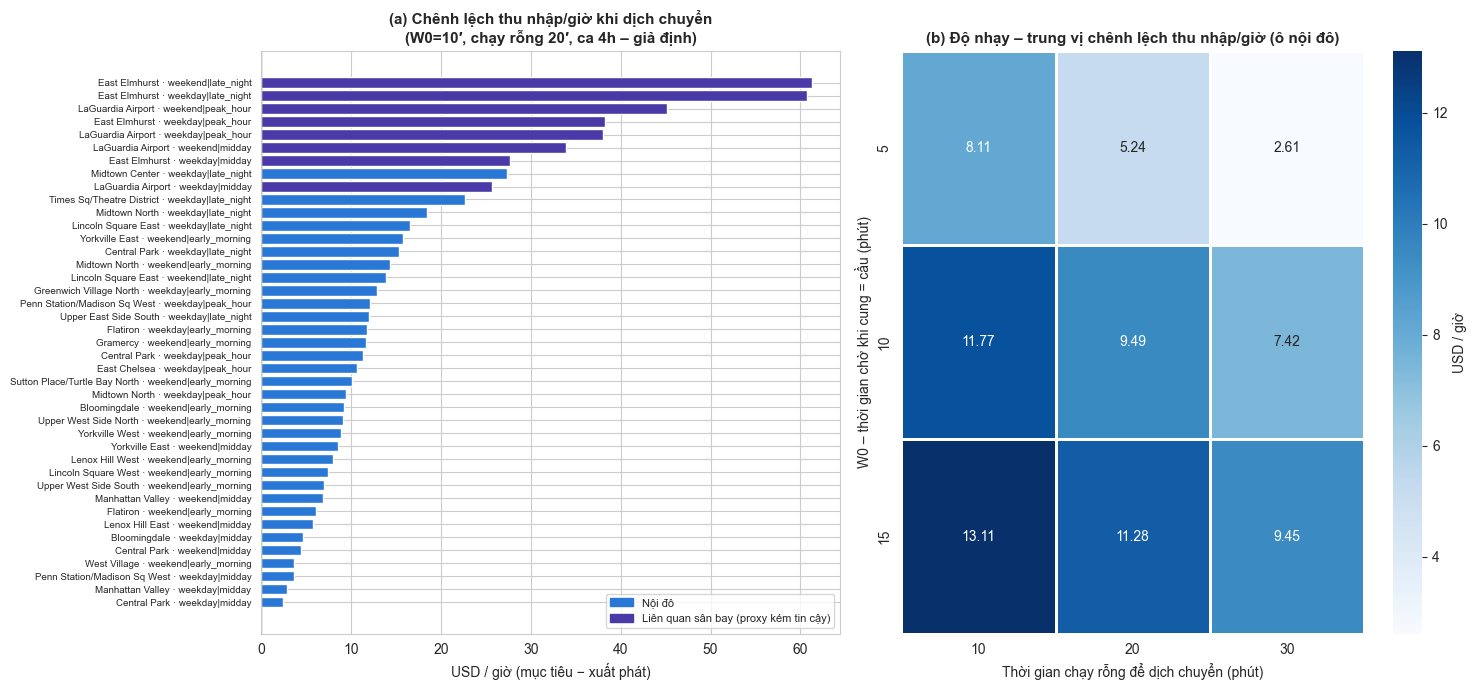

In [35]:
ALPHAS = [0.05, 0.10, 0.20]
sys_rows = []
for (group, tg), a in [((g, t), a) for g, t in [("urban", targets[~targets["airport_related"]]),
                                                ("airport-related", targets[targets["airport_related"]])]
                       for a in ALPHAS]:
    extra_trips = a * tg["trips"]                                     # per month
    sys_rows.append({
        "target group": group,
        "alpha (extra demand absorbed)": f"{a:.0%}",
        "extra_trips_per_month": extra_trips.sum(),
        "extra_revenue_usd_per_month": (extra_trips * tg["revenue_per_trip"]).sum(),
        "extra_card_tip_usd_per_month": (extra_trips * tg["avg_tip_usd"]
                                         * tg["card_ok_trips"] / tg["trips"]).sum(),
        "driver_hours_needed": (extra_trips * (tg["avg_duration"] + BASE_W0) / 60).sum(),
        "share_of_all_month_revenue": (extra_trips * tg["revenue_per_trip"]).sum() / zone_src["revenue"].sum(),
    })
system_impact = pd.DataFrame(sys_rows)
print(system_impact.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3.6))
piv = system_impact.pivot(index="alpha (extra demand absorbed)", columns="target group",
                          values="extra_revenue_usd_per_month").reindex(["5%", "10%", "20%"])
xx = np.arange(len(piv))
for i, (g, c, lab) in enumerate([("urban", C_BLUE, "Ô nội đô"), ("airport-related", C_VIOLET, "Ô sân bay")]):
    ax.bar(xx + (i - 0.5) * 0.38, piv[g] / 1000, width=0.36, color=c, label=lab)
ax.set_xticks(xx, piv.index)
ax.set_title("Doanh thu tăng thêm/tháng nếu ô mục tiêu hấp thụ thêm α% chuyến (cận trên, giả định)")
ax.set_xlabel("α – tỷ lệ chuyến tăng thêm")
ax.set_ylabel("Nghìn USD / tháng")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
s = scen.sort_values("gain_per_hour")
axes[0].barh(s["pickup_zone"] + " · " + s["slot"], s["gain_per_hour"],
             color=np.where(s["airport_related"], C_VIOLET, C_BLUE))
axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=C_BLUE), plt.Rectangle((0, 0), 1, 1, color=C_VIOLET)],
               labels=["Nội đô", "Liên quan sân bay (proxy kém tin cậy)"], fontsize=8, loc="lower right")
axes[0].axvline(0, color=C_GREY, lw=1)
axes[0].set_title(f"(a) Chênh lệch thu nhập/giờ khi dịch chuyển\n(W0={BASE_W0}′, chạy rỗng {BASE_DEADHEAD}′, ca {SHIFT_HOURS}h – giả định)")
axes[0].set_xlabel("USD / giờ (mục tiêu − xuất phát)")
axes[0].tick_params(axis="y", labelsize=7)
sns.heatmap(sens.astype(float), annot=True, fmt=".2f", cmap="Blues", ax=axes[1],
            cbar_kws={"label": "USD / giờ"}, linewidths=2, linecolor="white")
axes[1].set_title("(b) Độ nhạy – trung vị chênh lệch thu nhập/giờ (ô nội đô)")
axes[1].set_xlabel("Thời gian chạy rỗng để dịch chuyển (phút)")
axes[1].set_ylabel("W0 – thời gian chờ khi cung = cầu (phút)")
plt.tight_layout()
plt.show()

**Insight:** dịch chuyển tới ô nội đô "tip cao – ít xe" chỉ có lợi **nhờ chờ khách ít hơn**; bản thân chuyến ở đó không đắt hơn hay tip nhiều hơn.

**[BẰNG CHỨNG TỪ DỮ LIỆU + GIẢ ĐỊNH KỊCH BẢN]**
- 33 ô nội đô: trung vị **+9.49 USD/giờ** (W0 = 10 phút, chạy rỗng 20 phút); độ nhạy **+2.61 → +13.11 USD/giờ**, dương ở mọi tổ hợp.
- Bỏ giả định chờ: chênh lệch doanh thu/giờ có khách trung vị **0.01 USD**, dương ở **52%** ô → toàn bộ lợi ích đến từ giả định thời gian chờ.
- 8 ô sân bay: +38.15 USD/giờ — **không tin cậy** (bỏ qua hàng chờ).
- Hệ thống (cận trên): ô nội đô hấp thụ thêm 5 / 10 / 20% chuyến → **+348k / +696k / +1.39 triệu USD/tháng** (**0.37 / 0.73 / 1.47%** doanh thu tháng); cần 7.1k–28.5k giờ tài xế.

**Tác động:** tài xế — lợi ích cá nhân thực nhưng nhỏ, phụ thuộc thời gian chờ thật; nền tảng — đòn bẩy toàn hệ thống **≤ 1.5% doanh thu**, phải A/B test trước khi chi thưởng.

## 5.6. Đề xuất hành động & Deployment

### 5.6.1. DM1 có dùng được ở cấp tổng hợp zone × khung giờ không?

Test cells with >= 50 card_ok trips: 442 | Spearman = 0.6201 | MAE = 0.0236


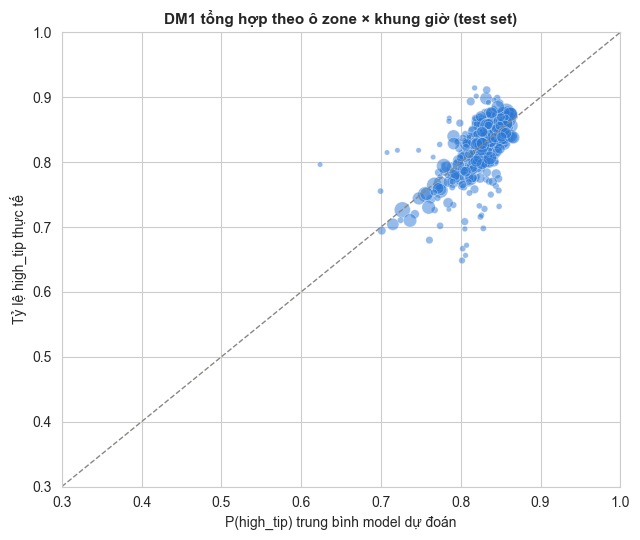

In [36]:
tm = test_meta[test_meta["card_ok"] & test_meta["pu_in_month"] & ~test_meta["PULocationID"].isin(UNKNOWN_ZONE_IDS)]
calib = tm.groupby(["PULocationID", "pickup_zone", "slot"]).agg(
    n=("high_tip", "size"), actual=("high_tip", "mean"), predicted=("p_hgb", "mean")).reset_index()
calib = calib[calib["n"] >= 50]
rho_c, _ = spearmanr(calib["predicted"], calib["actual"])
mae_c = (calib["predicted"] - calib["actual"]).abs().mean()
print(f"Test cells with >= 50 card_ok trips: {len(calib)} | Spearman = {rho_c:.4f} | MAE = {mae_c:.4f}")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(calib["predicted"], calib["actual"], s=np.sqrt(calib["n"]) * 2, color=C_BLUE, alpha=0.5,
           edgecolor="white", linewidth=0.4)
ax.plot([0, 1], [0, 1], ls="--", lw=1, color=C_GREY)
ax.set_xlim(0.3, 1)
ax.set_ylim(0.3, 1)
ax.set_title("DM1 tổng hợp theo ô zone × khung giờ (test set)")
ax.set_xlabel("P(high_tip) trung bình model dự đoán")
ax.set_ylabel("Tỷ lệ high_tip thực tế")
plt.tight_layout()
plt.show()

**Insight:** gộp theo zone × khung giờ, DM1 dự đoán **đúng tỷ lệ high_tip** — nhưng high_tip không phải thứ tài xế cần (5.2.1).

**[BẰNG CHỨNG TỪ DỮ LIỆU]** 442 ô test (≥ 50 chuyến `card_ok`): Spearman dự đoán vs thực tế **0.6201**, sai số tuyệt đối TB **2.4 điểm %**.

**Tác động:** nền tảng — DM1 tổng hợp chỉ hữu ích để **theo dõi** tỷ lệ tip theo khu; muốn gợi ý cho tài xế cần model dự đoán tip USD / thu nhập/giờ.

### 5.6.2. Bảng gợi ý cụ thể (tổng hợp từ 5.3–5.5)

In [37]:
# Drivers: best target cells per slot by estimated gain (baseline assumptions)
driver_reco = (scen[(scen["gain_per_hour"] > 0) & ~scen["airport_related"]].sort_values(["slot", "gain_per_hour"], ascending=[True, False])
               .groupby("slot").head(2)[["slot", "pickup_borough", "pickup_zone", "high_tip_rate", "avg_tip_usd",
                                          "revenue_per_trip", "flow_ratio", "gain_per_hour"]])
print("Drivers - urban cells to reposition to (positive estimated gain, top 2 per slot; airport cells excluded):")
print(driver_reco.to_string(index=False))

# Platform: zone-bonus candidates = target cells where most cars currently arrive empty
platform_reco = targets.nlargest(8, "net_outflow_per_hour")[["pickup_borough", "pickup_zone", "slot",
                                                              "pickups_per_hour", "net_outflow_per_hour",
                                                              "high_tip_rate", "revenue_per_trip", "airport_related"]]
print("\nPlatform - zone-bonus / dispatch candidates (largest net outflow among target cells):")
print(platform_reco.to_string(index=False))

# Dispatch by DM2 cluster: economic difference that justifies separate rules
print("\nDM2 (k=5) - dispatch view:")
print(prof_k5[["share_trips", "share_revenue", "revenue_per_trip", "revenue_per_occ_hour",
               "airport_share", "avg_duration"]].to_string())

Drivers - urban cells to reposition to (positive estimated gain, top 2 per slot; airport cells excluded):
                 slot pickup_borough                  pickup_zone  high_tip_rate  avg_tip_usd  revenue_per_trip  flow_ratio  gain_per_hour
weekday|early_morning      Manhattan      Greenwich Village North         0.8576       3.5908           20.3946      0.7295        12.8433
weekday|early_morning      Manhattan                     Flatiron         0.8490       3.3846           19.0613      0.6679        11.8250
   weekday|late_night      Manhattan               Midtown Center         0.8518       3.8925           22.4449      0.4327        27.3422
   weekday|late_night      Manhattan    Times Sq/Theatre District         0.8471       4.1992           24.0374      0.5696        22.6708
       weekday|midday      Manhattan                 Bloomingdale         0.8527       3.8920           22.2322      0.7947         4.6060
       weekday|midday      Manhattan Penn Station/Madison Sq

### 5.6.3. Đề xuất hành động

**Nền tảng / hãng taxi**

| # | Hành động | Căn cứ (số liệu) |
|---|---|---|
| P1 | **Không** triển khai DM1 làm công cụ gợi ý thu nhập; dùng bảng **KPI lịch sử theo ô** (thu nhập/giờ, tip USD) | DM1 −2.66 USD/giờ; KPI lịch sử +7.00 → +24.60 USD/giờ (5.2.1) |
| P2 | Gắn cờ RatecodeID = 99 trước mọi báo cáo tip theo khu vực | Né sai 2,785 chuyến/ngày ở khu dân cư (5.2.2) |
| P3 | Điều phối xe rỗng ngược dòng chảy: sáng văn phòng → dân cư, tối ngược lại | Midtown Center/Hudson Yards sáng 2.84–2.97, tối 0.43 (5.5) |
| P4 | Thí điểm **thưởng khu vực + A/B test** ở ô nội đô net outflow lớn: Midtown Center đêm ngày thường (**93.2** chuyến/giờ phải có xe từ nơi khác), Midtown North cao điểm (65.7), Penn Station trưa (62.3), Times Sq đêm (60.9) | Lợi ích hệ thống ≤ 1.47% doanh thu → thí điểm nhỏ trước (5.5.2) |
| P5 | Lịch điều phối riêng cho cụm sân bay (DM2 k=6) | 8.5% chuyến – 23.9% doanh thu, 55.5 phút/chuyến (5.2.3) |
| P6 | Không thưởng theo net outflow ở sân bay khi chưa có dữ liệu bãi chờ | Proxy không thấy hàng chờ (5.5) |

**Tài xế** (ô nội đô có lợi ích ước tính dương, **[GIẢ ĐỊNH]** W0 = 10′)

| Khung giờ | Nên chạy | Lợi ích ước tính |
|---|---|---|
| Đêm ngày thường | Midtown Center, Times Sq/Theatre District | +27.34, +22.67 USD/giờ |
| Sáng sớm cuối tuần | Yorkville East, Midtown North | +15.81, +14.29 USD/giờ |
| Sáng sớm ngày thường | Greenwich Village North, Flatiron | +12.84, +11.83 USD/giờ |
| Cao điểm ngày thường | Penn Station/Madison Sq West, Central Park | +12.06, +11.38 USD/giờ |

- Chọn khu theo **tip USD và thu nhập/giờ**, không theo tỷ lệ tip %: sân bay tip **12.88 USD** vs **3.4–4.2 USD** ở lõi Manhattan.
- Rủi ro không tip cao nhất: khu ăn chơi Lower Manhattan **đêm cuối tuần** (9–12% chuyến không tip).

**Khách hàng**
- Minh bạch rằng % trên nút tip tính trên **tổng tiền gồm phụ phí** (56.4% chuyến bấm đúng 20%).
- Khung giờ thiếu xe theo proxy (UES/UWS sáng cuối tuần, Midtown đêm ngày thường) → nên đặt xe sớm.

### 5.6.4. Deployment DM1 / DM2

| | Dùng cho | Không dùng cho | Rủi ro | Theo dõi |
|---|---|---|---|---|
| **DM1** | Chỉ ở cấp tổng hợp (Spearman 0.62 theo ô), **kèm tip USD**, sau khi lặp lại vòng CRISP-DM | Gợi ý thu nhập cho tài xế; dự đoán từng chuyến; rút xe khỏi khu vực | Học artifact; ngược KPI tài xế (ρ = −0.41 với tip USD); rủi ro công bằng theo khu vực | Tỷ lệ RatecodeID = 99; phân bố tip/(tổng − tip); calibration theo ô hằng tháng |
| **DM2** | Lịch điều phối ngày thường / cuối tuần / sân bay (k=6) | Dự đoán tip, định giá | Silhouette 0.21; chỉ có borough; 1 tháng | Tỷ trọng cụm theo tuần (drift); doanh thu/giờ có khách theo cụm |

## 5.7. Review quy trình & bước tiếp theo

### 5.7.1. Đối chiếu tiêu chí thành công (Business Understanding 1.4 & 1.7)

In [38]:
auc_hgb, auc_lr = roc_auc_score(y1_test, p_hgb), roc_auc_score(y1_test, p_lr)
auc_ok = model_by_subset.loc[1, "AUC"]
checklist = pd.DataFrame([
    ["DM1", "AUC vượt rõ baseline (Dummy 0.5, LogReg)",
     f"HGB {auc_hgb:.4f} | LogReg {auc_lr:.4f} | Dummy 0.5000", "Đạt" if auc_hgb > auc_lr > 0.5 else "Không đạt"],
    ["DM1", "Không dùng Accuracy làm thước đo chính", "Dùng precision/recall từng lớp, lift, gain, chi phí", "Đạt"],
    ["DM1", "AUC khi loại artifact RatecodeID=99", f"{auc_ok:.4f}", "Cần lưu ý" if auc_ok < auc_hgb else "Đạt"],
    ["DM1", "Diễn giải được yếu tố quan trọng",
     f"Nhóm giá cước giảm AUC {imp_group.iloc[0]['auc_drop_mean']:.4f}", "Đạt (cảnh báo: nhãn phụ thuộc fare)"],
    ["DM2", "Silhouette > 0.3", f"k=5: {sil[5]:.4f} | k=6: {sil[6]:.4f}",
     "Đạt" if max(sil.values()) > 0.3 else "Không đạt"],
    ["DM2", "Cụm đặt tên & diễn giải được", "Profile thời gian/không gian + kinh tế (5.1.7)", "Đạt"],
    ["Business", "Chuyển thành khuyến nghị hành động", f"{int(flow_elig['is_target'].sum())} ô mục tiêu, bảng 5.6.2", "Đạt (dựa trên proxy)"],
    ["Business", "DM1 tăng thu nhập/giờ cho tài xế (backtest 5.2.1)",
     f"{backtest.loc['DM1: top 20% P(high_tip)', 'delta_rev_per_occ_hour']:+.2f} USD/giờ có khách so với hiện trạng",
     "Đạt" if backtest.loc["DM1: top 20% P(high_tip)", "delta_rev_per_occ_hour"] > 0 else "Không đạt"],
    ["Business", "Nêu rõ giới hạn", "Tip tiền mặt, proxy cung, 1 tháng, artifact 99", "Đạt"],
], columns=["Bài toán", "Tiêu chí", "Kết quả đo được", "Đánh giá"])
print(checklist.to_string(index=False))

Bài toán                                          Tiêu chí                                     Kết quả đo được                            Đánh giá
     DM1          AUC vượt rõ baseline (Dummy 0.5, LogReg)           HGB 0.7164 | LogReg 0.6825 | Dummy 0.5000                                 Đạt
     DM1            Không dùng Accuracy làm thước đo chính Dùng precision/recall từng lớp, lift, gain, chi phí                                 Đạt
     DM1               AUC khi loại artifact RatecodeID=99                                              0.6226                           Cần lưu ý
     DM1                  Diễn giải được yếu tố quan trọng                       Nhóm giá cước giảm AUC 0.2044 Đạt (cảnh báo: nhãn phụ thuộc fare)
     DM2                                  Silhouette > 0.3                           k=5: 0.2054 | k=6: 0.2416                           Không đạt
     DM2                      Cụm đặt tên & diễn giải được      Profile thời gian/không gian + kinh tế (5.1.7)        

### 5.7.2. Điểm mạnh / điểm yếu

| | Mạnh | Yếu / còn tồn tại |
|---|---|---|
| **Dữ liệu** | 3.9 triệu chuyến, có zone/giờ/cước/tip thẻ; pipeline tái tạo được 100% | Không có tip tiền mặt; **22.6%** chuyến không báo thanh toán; **artifact RatecodeID = 99** lọt qua Preparation; không có ID xe/khách; 1 tháng |
| **DM1** | Vượt LogReg/Dummy; tổng hợp theo ô khớp thực tế (Spearman 0.62) | AUC **0.62** khi loại artifact; nhãn bị chi phối bởi cơ chế phụ phí/nút bấm; chỉ có borough, không có zone |
| **DM2** | Tái tạo chính xác; cụm khác rõ về doanh thu/giờ; k=6 tách được sân bay | Silhouette 0.21 < 0.3; không phân biệt tip |
| **Phân tích business** | Tách bằng chứng/giả thuyết; backtest, tác động khách, kịch bản có độ nhạy | Proxy cung sai ở sân bay; lợi ích dịch chuyển phụ thuộc giả định chờ; không quan sát được cầu bị bỏ lỡ |

### 5.7.3. Hướng cải thiện

1. **Data Preparation:** gắn cờ/loại chuyến thẻ `RatecodeID = 99` ghi trực tiếp; kiểm tra "tip = 0 và phụ phí luật định = 0".
2. **Nhãn DM1:** tính tip % trên **tổng tiền trước tip**, hoặc nhãn "**không tip / dưới mức gợi ý thấp nhất**"; thêm bài toán hồi quy **tip USD** và **thu nhập/giờ** (KPI tài xế).
3. **Đặc trưng:** `PULocationID`/`DOLocationID` (target encoding), `RatecodeID`, `VendorID`, cờ `Airport_fee`.
4. **DM2:** chuyển sang k=6 cho điều phối; thay borough one-hot bằng zone/toạ độ tâm zone.
5. **Dữ liệu ngoài:** nhiều tháng, Census theo zone (H8), dữ liệu bãi chờ sân bay, FHV (Uber/Lyft) để ước lượng cầu bị bỏ lỡ.
6. **Kỹ thuật:** lưu model (`joblib`) và file gán cụm ở Modeling.

### 5.7.4. Quyết định

| Thành phần | Quyết định | Lý do (số liệu) |
|---|---|---|
| **DM2** | **Tiếp tục → Deployment thí điểm** (ưu tiên k=6) | Cụm khác rõ về doanh thu/giờ; cụm sân bay 8.5% chuyến – 23.9% doanh thu |
| **Bản đồ zone × khung giờ** (5.3–5.5) | **Tiếp tục, có A/B test** | Thống kê mô tả trực tiếp; lợi ích dịch chuyển phụ thuộc giả định chờ |
| **DM1 cấp từng chuyến** | **Lặp lại CRISP-DM** (Preparation → Modeling) | Năng lực chủ yếu từ artifact (AUC 0.72 → 0.62); backtest −2.66 USD/giờ có khách so với hiện trạng (5.2.1) |
| **DM1 cấp tổng hợp** | **Không** dùng cho tài xế; chỉ theo dõi nội bộ tới khi lặp lại xong | Khớp theo ô (Spearman 0.62) nhưng ngược KPI tài xế (ρ = −0.41 với tip USD) |
| **Bảng KPI lịch sử theo ô** (thu nhập/giờ, tip USD) | **Thay thế DM1** trong gợi ý tài xế, có A/B test | +7.00 → +24.60 USD/giờ có khách trong backtest |

**Bước tiếp theo:** sửa Preparation (cờ RatecodeID = 99) → định nghĩa lại nhãn/KPI → train lại với zone → đánh giá lại bằng đúng bộ chỉ số của notebook này (backtest 5.2.1, tác động khách 5.2.2, calibration theo ô).